# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

Free ideas for extra work:
Set a baseline and then try to improve it.

* can we fetch some external data to improve our results? like prompt the models with new prompts to build a larger dataset?
* analyse patterns in the text: by model look at punctuation, sentence length, word length, etc. and see if there are any patterns that can be used to improve the classification task.
* explore the use of ensemble methods to combine the predictions of multiple models and potentially improve the overall performance.

* extract different features from the text, such as n-grams, part-of-speech tags, or named entities, and see if they can enhance the classification performance / create more informed UNK tokens
* create multimodal represntations: stylometric features, embeddings from different embedders, etc. and see if they can enhance the classification performance

---
# Our project: Name that LLM

## 0. Reproducibility

Every experiment below is seeded so anyone can re-run it and get the same numbers.

- **During development** use one seed (`MODE = "dev"`), so iterations stay fast.
- **For reported results** switch to `MODE = "report"`: every experiment runs once per seed (5 seeds × k folds). We report the mean and a 95% interval across runs. `BenavoliCorrelatedT(..., runs=len(SEEDS))` in `part1.analysis` accounts for the fold overlap.
- Call `set_seed(seed)` **right before** every split / training call. `part1.smlp.train_neural_network_model` does not seed PyTorch itself, so without this the MLP weights and batch order change on every run.
- The seed controls the fold split (`cross_validation_split(..., seed=seed)`) **and** the model's initialisation, so each run is a different split + initialisation.

In [1]:
# ---- Reproducibility setup: run this cell first ----
import os
import random
import sys
import warnings
from pathlib import Path

import numpy as np
import torch

warnings.simplefilter(action="ignore", category=FutureWarning)

# Paths (this notebook lives in root/part1)
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import part1  # noqa: E402  (course helpers: experiment, loglin, smlp, analysis, ...)

DATA_DIR = ROOT / "data" / "name-that-llm"
RESULTS_DIR = ROOT / "outputs" / "part1"   # gitignored
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Seeds
MODE = "dev"                    # "dev" -> 1 seed (fast) | "report" -> 5 seeds (for the final numbers)
DEV_SEEDS = [0]
REPORT_SEEDS = [0, 1, 2, 3, 4]
SEEDS = DEV_SEEDS if MODE == "dev" else REPORT_SEEDS
NUM_FOLDS = 5

SPLIT_SEED = 42


def set_seed(seed: int) -> None:
    """Seed every RNG we use (Python, NumPy, PyTorch) and make torch deterministic where possible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)  # only affects subprocesses; kernel hash seed is fixed at startup
    torch.use_deterministic_algorithms(True, warn_only=True)


def summarise_runs(scores, confidence=0.95):
    """Mean and t-based CI over independent runs (e.g. one mean accuracy per seed)."""
    from scipy import stats
    scores = np.asarray(scores, dtype=float)
    mean = scores.mean()
    if len(scores) < 2:
        return mean, (np.nan, np.nan)
    half = stats.t.ppf((1 + confidence) / 2, len(scores) - 1) * stats.sem(scores)
    return mean, (mean - half, mean + half)


set_seed(SEEDS[0])
print(f"MODE={MODE} | SEEDS={SEEDS} | folds={NUM_FOLDS} | torch {torch.__version__} | numpy {np.__version__}")

MODE=dev | SEEDS=[0] | folds=5 | torch 2.15.0 | numpy 2.5.4


## 1. Data: Name that LLM

**What they ask:** choose a dataset, spend time understanding it and compute some statistics (e.g. how many instances of each label).

**Our task:** given a text, predict which LLM (`model` column) wrote it. Kaggle competition: [name-that-llm](https://www.kaggle.com/competitions/name-that-llm).

In [2]:
import pandas as pd

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
print(train_df.shape, test_df.shape)
display(train_df.head())

# Label distribution
display(train_df["model"].value_counts().to_frame("count"))

# Prompts: how many, and how many models answer each one?
print("unique prompts:", train_df["prompt_id"].nunique())
display(train_df.groupby("prompt_id")["model"].nunique().describe())

# Length per model (characters / whitespace tokens)
train_df["n_chars"] = train_df["text"].str.len()
train_df["n_words"] = train_df["text"].str.split().str.len()
display(train_df.groupby("model")[["n_chars", "n_words"]].mean().sort_values("n_words"))

# Length per model (characters / whitespace tokens)
train_df["n_chars"] = train_df["text"].str.len()
train_df["n_words"] = train_df["text"].str.split().str.len()
display(train_df.groupby("model")[["n_chars", "n_words"]].median().sort_values("n_words"))

# Outcome space: map label names <-> integer ids (as in the tutorial)
outcome_space = part1.clslib.NamedClasses(sorted(train_df["model"].unique()))
pairs = [(t, outcome_space.index(m)) for t, m in zip(train_df["text"], train_df["model"])]
print(len(outcome_space), "classes")

(2699, 4) (3, 2)


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


,count
model,
qwen3.8-max,150
claude-sonnet-5,150
gemini-3.6-flash,150
gpt-5.6-terra,150
glm-5.3-flash,150
gemini-3.1-pro-preview,150
gemini-3.8-flash,150
claude-opus-4-6,150
gpt-5.6-luna,150


unique prompts: 150


count    150.000000
mean      17.993333
std        0.081650
min       17.000000
25%       18.000000
50%       18.000000
75%       18.000000
max       18.000000
Name: model, dtype: float64

,n_chars,n_words
model,,
gemini-3.8-flash,706.200000,100.680000
kimi-k3,690.133333,107.366667
qwen3.8-max,707.733333,108.346667
gpt-5.5,698.646667,110.273333
glm-5.3,710.273333,110.340000
gemini-3.6-flash,758.560000,111.153333
claude-fable-5,731.020134,112.496644
gpt-5.6-terra,746.580000,113.260000
claude-opus-4-6,771.206667,115.146667


,n_chars,n_words
model,,
gemini-3.8-flash,583.0,84.0
kimi-k3,594.5,89.0
gemini-3.6-flash,634.5,95.5
glm-5.3,616.5,96.0
qwen3.8-max,625.0,98.5
claude-opus-4-6,687.5,98.5
claude-sonnet-5,707.0,99.5
claude-fable-5,646.0,100.0
gpt-5.6-terra,648.5,100.5


18 classes


### Data Splitting

In [3]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=SPLIT_SEED)
train_idx, test_idx = next(gss.split(train_df, y=train_df["model"], groups=train_df["prompt_id"]))

train_split_df = train_df.iloc[train_idx].reset_index(drop=True)
test_split_df = train_df.iloc[test_idx].reset_index(drop=True)

train_split_df.to_csv(DATA_DIR / "split_train.csv", index=False)
test_split_df.to_csv(DATA_DIR / "split_test.csv", index=False)

# Verify the split is correct
assert train_split_df["prompt_id"].nunique() == 0.8 * train_df["prompt_id"].nunique()
assert test_split_df["prompt_id"].nunique() == 0.2 * train_df["prompt_id"].nunique()
assert set(train_split_df["prompt_id"]).isdisjoint(test_split_df["prompt_id"])

print(len(train_split_df), len(test_split_df))

2159 540


In [4]:
#statistical test for 

## Step 1 · Data audit (neural track)

**Why:** before choosing representations, we check what the classes differ on (length, punctuation, formatting) and whether anything leaks between train and test. These numbers feed the *data and metrics* slide.

In [5]:
# Shared objects for all neural-track steps: harness, label ids, families, figure style.
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from shared import analysis as A
from shared import eval_harness as H
from shared.data import FAMILIES, FAMILY_COLOR, family, load_data  # one definition for all three tracks

FIG_DIR = ROOT / "part1" / "figures"
FIG_DIR.mkdir(exist_ok=True)

DATA = load_data()                    # same rows as train_split_df / test_split_df above
assert DATA.train["id"].tolist() == train_split_df["id"].tolist()
CLASSES, CLASS_ID, CLASS_ORDER = DATA.classes, DATA.class_id, DATA.class_order

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

# Train split = the only data used for CV. Test split = touched once, in step 7.
d = train_split_df
y = d["model"].map(CLASS_ID).to_numpy()
groups = d["prompt_id"].to_numpy()
y_test = test_split_df["model"].map(CLASS_ID).to_numpy()
print(len(d), "train /", len(test_split_df), "test passages;", len(CLASSES), "classes")

2159 train / 540 test passages; 18 classes


passages per class: min 149 max 150 | total 2699


model,gpt-5.5,gpt-5.6-luna,gpt-5.6-sol,gpt-5.6-terra,gpt-6-astra,claude-fable-5,claude-opus-4-6,claude-opus-4-8,claude-opus-5,claude-sonnet-5,gemini-3.1-pro-preview,gemini-3.6-flash,gemini-3.7-flash,gemini-3.8-flash,glm-5.3,glm-5.3-flash,qwen3.8-max,kimi-k3
all,150,150,150,150,150,149,150,150,150,150,150,150,150,150,150,150,150,150
train_split,120,120,120,120,120,119,120,120,120,120,120,120,120,120,120,120,120,120
test_split,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30,30


,n_chars,n_words,n_chars,n_words,n_chars,n_words,n_chars,n_words,n_chars,n_words
,mean,mean,50%,50%,std,std,min,min,max,max
model,,,,,,,,,,
gpt-5.5,699.0,110.0,644.0,104.0,343.0,55.0,230.0,39.0,1516.0,245.0
gpt-5.6-luna,767.0,115.0,673.0,104.0,377.0,58.0,270.0,38.0,1686.0,246.0
gpt-5.6-sol,779.0,119.0,748.0,112.0,390.0,60.0,254.0,40.0,1714.0,261.0
gpt-5.6-terra,747.0,113.0,648.0,100.0,363.0,54.0,272.0,43.0,1724.0,239.0
gpt-6-astra,750.0,118.0,678.0,106.0,372.0,59.0,245.0,36.0,1659.0,256.0
claude-fable-5,731.0,112.0,646.0,100.0,372.0,58.0,259.0,39.0,1875.0,252.0
claude-opus-4-6,771.0,115.0,688.0,98.0,387.0,61.0,287.0,42.0,1766.0,274.0
claude-opus-4-8,810.0,124.0,732.0,109.0,389.0,62.0,277.0,42.0,1657.0,251.0


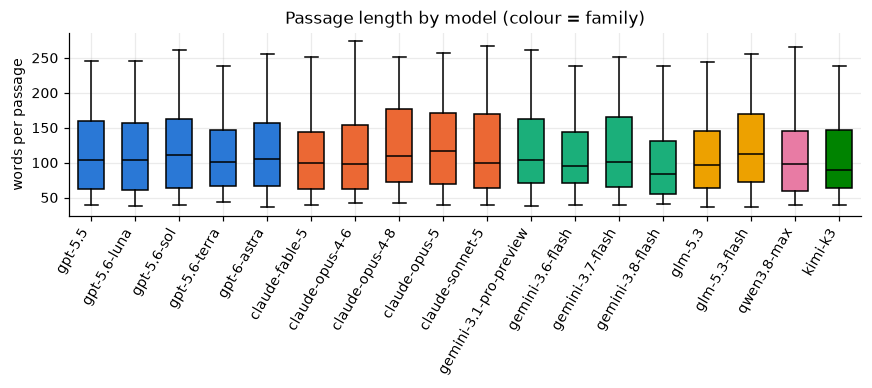

In [6]:
# Label counts and length distributions per class (full labelled data)
full = train_df.assign(family=train_df["model"].map(family),
                       n_chars=train_df["text"].str.len(),
                       n_words=train_df["text"].str.split().str.len())
counts = pd.DataFrame({"all": full["model"].value_counts(),
                       "train_split": d["model"].value_counts(),
                       "test_split": test_split_df["model"].value_counts()}).loc[CLASS_ORDER]
print("passages per class: min", counts["all"].min(), "max", counts["all"].max(), "| total", counts["all"].sum())
length_stats = full.groupby("model")[["n_chars", "n_words"]].describe().loc[CLASS_ORDER]
length_stats = length_stats.loc[:, (slice(None), ["mean", "50%", "std", "min", "max"])].round(0)
display(counts.T)
display(length_stats)

fig, ax = plt.subplots(figsize=(8, 3.6))
data = [full.loc[full["model"] == m, "n_words"] for m in CLASS_ORDER]
bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops={"color": "black"}, flierprops={"markersize": 3})
for patch, m in zip(bp["boxes"], CLASS_ORDER):
    patch.set_facecolor(FAMILY_COLOR[family(m)])
ax.set_xticks(range(1, len(CLASS_ORDER) + 1), CLASS_ORDER, rotation=60, ha="right")
ax.set_ylabel("words per passage")
ax.set_title("Passage length by model (colour = family)")
fig.tight_layout(); fig.savefig(FIG_DIR / "s1_length_by_model.png", dpi=200); plt.show()

,newlines,md_headers,bullets,bold,em_dash,curly_quotes,straight_quotes,semicolons,colons,non_ascii
model,,,,,,,,,,
gpt-5.5,0.0,0.0,0.0,0.0,0.21,0.91,0.23,0.83,0.93,1.17
gpt-5.6-luna,0.0,0.0,0.0,0.0,0.49,1.11,0.02,0.57,0.99,1.69
gpt-5.6-sol,0.0,0.0,0.0,0.0,0.38,1.27,0.00,0.84,0.91,1.76
gpt-5.6-terra,0.0,0.0,0.0,0.0,0.37,0.91,0.05,0.64,0.94,1.41
gpt-6-astra,0.0,0.0,0.0,0.0,0.11,0.89,0.17,0.69,0.89,1.11
claude-fable-5,0.0,0.0,0.0,0.0,1.50,0.00,1.20,0.46,0.76,1.60
claude-opus-4-6,0.0,0.0,0.0,0.0,1.30,0.00,1.25,0.15,0.46,1.43
claude-opus-4-8,0.0,0.0,0.0,0.0,0.97,0.00,1.17,0.26,0.56,1.03
claude-opus-5,0.0,0.0,0.0,0.0,1.50,0.00,1.28,0.66,0.96,1.61


share of passages with >=1 occurrence:
 {'newlines': 0.0, 'md_headers': 0.0, 'bullets': 0.0, 'bold': 0.0, 'em_dash': 0.39, 'curly_quotes': 0.225, 'straight_quotes': 0.321, 'semicolons': 0.387, 'colons': 0.521, 'non_ascii': 0.578}


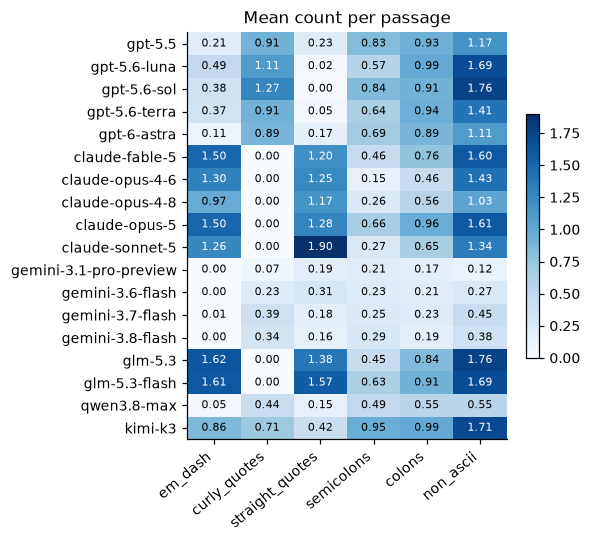

In [7]:
# Formatting / typography statistics per class (mean count per passage)
def formatting_features(texts: pd.Series) -> pd.DataFrame:
    return pd.DataFrame({
        "newlines": texts.str.count("\n"),
        "md_headers": texts.str.count(r"(?m)^#{1,6} "),
        "bullets": texts.str.count(r"(?m)^\s*(?:[-*•]|\d+\.)\s"),
        "bold": texts.str.count(r"\*\*[^*]+\*\*"),
        "em_dash": texts.str.count("—"),
        "curly_quotes": texts.str.count("[“”‘’]"),
        "straight_quotes": texts.str.count("[\"']"),
        "semicolons": texts.str.count(";"),
        "colons": texts.str.count(":"),
        "non_ascii": texts.apply(lambda s: sum(ord(c) > 127 for c in s)),
    })


fmt = formatting_features(full["text"]).assign(model=full["model"])
fmt_by_class = fmt.groupby("model").mean().loc[CLASS_ORDER].round(2)
display(fmt_by_class)
print("share of passages with >=1 occurrence:\n", (fmt.drop(columns="model") > 0).mean().round(3).to_dict())

cols = ["em_dash", "curly_quotes", "straight_quotes", "semicolons", "colons", "non_ascii"]
fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(fmt_by_class[cols].to_numpy(), cmap="Blues", aspect="auto")
ax.set_xticks(range(len(cols)), cols, rotation=40, ha="right"); ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
for i in range(len(CLASS_ORDER)):
    for j, c in enumerate(cols):
        v = fmt_by_class[c].iloc[i]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 1.0 else "black")
ax.grid(False); ax.set_title("Mean count per passage")
fig.colorbar(im, ax=ax, shrink=0.6); fig.tight_layout()
fig.savefig(FIG_DIR / "s1_typography_by_model.png", dpi=200); plt.show()

In [8]:
# Exact and near duplicates (char 3-5-gram TF-IDF cosine), and prompt overlap between splits
from sklearn.feature_extraction.text import TfidfVectorizer

texts = full["text"]
print("exact duplicate texts:", texts.duplicated().sum())
X_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True).fit_transform(texts)
S = (X_char @ X_char.T).toarray()
np.fill_diagonal(S, 0)
print("max pairwise cosine:", S.max().round(3))
for th in (0.95, 0.9, 0.8):
    print(f"  pairs with cosine > {th}: {(np.triu(S) > th).sum()}")
i, j = np.unravel_index(S.argmax(), S.shape)
print(f"closest pair: {full.model[i]} vs {full.model[j]}, same prompt: {full.prompt_id[i] == full.prompt_id[j]}")
del S

print("\ncolumns train.csv:", list(train_df.columns), "| test.csv:", list(test_df.columns))
print("prompts shared between Kazik's train and test split:",
      len(set(d["prompt_id"]) & set(test_split_df["prompt_id"])))
print("passages per prompt:", train_df.groupby("prompt_id").size().value_counts().to_dict())
print("NFC changes", (texts != texts.map(lambda s: unicodedata.normalize("NFC", s))).sum(),
      "texts; NFKC would change", (texts != texts.map(lambda s: unicodedata.normalize("NFKC", s))).sum())

exact duplicate texts: 0


max pairwise cosine: 0.691
  pairs with cosine > 0.95: 0
  pairs with cosine > 0.9: 0
  pairs with cosine > 0.8: 0
closest pair: claude-fable-5 vs claude-opus-4-8, same prompt: True

columns train.csv: ['id', 'prompt_id', 'text', 'model', 'n_chars', 'n_words'] | test.csv: ['id', 'text']
prompts shared between Kazik's train and test split: 0
passages per prompt: {18: 149, 17: 1}
NFC changes 0 texts; NFKC would change 12


**Findings (step 1)**

- **Labels:** 18 classes, 149–150 passages each (2,699 in total; `claude-fable-5` has 149). Kazik's split: 2,159 train / 540 test, 120 vs 30 prompts, 30 test passages per class.
- **Prompt column:** `prompt_id` exists. Every prompt is answered by all 18 models (one by 17), so the topic carries no label information, but passages answering the same prompt are correlated. Kaggle states that test prompts never appear in `train.csv`, so Kazik's prompt-grouped split and our grouped folds (step 2) match the competition setting. 0 prompts are shared between our splits.
- **Length:** the means range from 101 words (gemini-3.8-flash) to 124 (claude-opus-4-8), but within-class spread is much larger (Kaggle: lengths "vary randomly between 40 and 250 words"). The length-only baseline in step 2 checks how much this helps.
- **Formatting:** no newlines, markdown headers, bullets or bold anywhere: every passage is a single plain paragraph. The markdown cue reported by Sun et al. (2025) is therefore absent. Typography is very informative at the **family** level: Claude and GLM never use curly quotes; GPT uses curly quotes and almost no straight ones; Gemini almost never uses em dashes; Claude and GLM use more than one em dash per passage.
- **Duplicates:** no exact duplicates; the highest char-n-gram cosine is 0.69 (two answers to the same prompt), so there are no near-duplicates to remove.
- **Metric:** the Kaggle metric is **balanced accuracy** (mean per-class recall). The hidden test set (~4,000 passages) is not class-balanced, so we use balanced accuracy as the primary metric.
- **Confound (no action):** Claude models launched from August 2026 bias token sampling with a watermark, and Gemini API text may carry SynthID; GPT API watermarking is off by default. We cannot detect these without the providers' keys, but they may shift token statistics that our classifiers pick up.
- Token counts per tokeniser are reported in step 4, once the tokenisers are fixed.

## Step 2 · Evaluation protocol (fixed before any model is trained)

**Why:** every comparison (ours and Liam's) has to use the same folds, metric, tuning rule and statistical test, otherwise the numbers can't be compared. All of it lives in `shared/eval_harness.py`.

- **Folds:** `StratifiedGroupKFold(5)` grouped by `prompt_id`, on Kazik's train split only. Grouping is required because test prompts are unseen (Kaggle) and passages for the same prompt share content. Repeated **R = 10** times (different shuffles, seeds 42–51) for cheap models; the fine-tuned model (step 6.5) uses **R = 1** (5 folds), because one fine-tuning fold costs minutes, not seconds. Indices are saved in `shared/folds.json` (by passage `id`); Kazik, Liam and we all load this file.
- **Metric:** balanced accuracy (Kaggle) is primary; accuracy and macro-F1 are also reported. With grouped folds each validation fold has 431–432 passages, about 24 per class.
- **Tuning: nested.** Inside each outer training fold, 20% of its prompts are held out (grouped) as the inner validation set. The grid point with the best inner balanced accuracy is refit on the full outer training fold and scored once on the outer fold. The MLPs use the same inner set for early stopping and are refit for the selected number of epochs. Because the outer fold is never used for selection, the reported scores aren't inflated by tuning.
- **Bayesian comparison:** Bayesian correlated t-test (Benavoli et al., 2017) on paired per-fold scores, with ρ = n_test / n_total = 432 / 2,159 ≈ 0.20, computed from the folds. Our implementation matches `baycomp.two_on_single` exactly (checked below).
- **ROPE = 1 percentage point of balanced accuracy.** That is about 4 passages per 432-passage fold. Differences below this are not practically meaningful for us: (i) the binomial standard error of a single test-set score at about 70% accuracy is √(0.7·0.3/540) ≈ 2 pp on our 540-passage test split, so a < 1 pp difference couldn't be confirmed on held-out data anyway; (ii) on Kaggle's ~4,000 passages, 1 pp is about 40 passages, which is roughly the gap between neighbouring leaderboard positions we would care about. (The brief estimated 540 passages per fold, which is the size of the test split; the CV folds hold 432.)
- **Test split:** used once, in step 7.

In [9]:
# Build (once) and load the shared folds
R_CHEAP, R_FINETUNE = 10, 1
if not H.FOLDS_PATH.exists():
    H.save_folds(H.make_folds(d["id"], y, groups, repeats=R_CHEAP))
FOLDS = H.load_folds(d["id"].tolist())                          # 10 x 5 = 50 folds
FOLDS_FT = H.load_folds(d["id"].tolist(), repeats=R_FINETUNE)   # first repeat only
for r, k, tr, te in FOLDS:
    assert set(groups[tr]).isdisjoint(groups[te])
print(len(FOLDS), "folds | test sizes", sorted({len(te) for *_, te in FOLDS}),
      "| rho =", round(np.mean([len(te) / (len(tr) + len(te)) for *_, tr, te in FOLDS]), 4))

50 folds | test sizes [431, 432] | rho = 0.2


In [10]:
# Baselines on the protocol: majority class and length-only logistic regression
import baycomp

from shared.data import length_features

maj = pd.DataFrame([H.scores(y[te], np.full(len(te), np.bincount(y[tr]).argmax())) for *_, tr, te in FOLDS])
X_len = length_features(d["text"])
RESULTS = {}  # name -> run_cv result; every model/representation lands here
RECOMPUTE = False  # True: ignore saved results in shared/results/ and re-run every CV


def cv(name, X, model, folds=None, **kw):
    """run_cv + save to shared/results/, or load the saved result (same name, same number of folds)."""
    folds = FOLDS if folds is None else folds
    saved = H.load_results(name.replace("/", "__") + ".json")
    if saved and not RECOMPUTE and len(saved[name]["folds"]) == len(folds):
        RESULTS[name] = saved[name]
        ba = H.fold_scores(RESULTS[name])
        print(f"{name:34s} bal.acc {ba.mean():.4f} ± {ba.std():.4f}  (loaded, {len(ba)} folds)")
    else:
        RESULTS[name] = H.run_cv(X, y, groups, folds, model, name=name, **kw)
        H.save_result(RESULTS[name])
    return RESULTS[name]


cv("length/logreg", X_len, "logreg")
display(pd.DataFrame({"majority": maj.mean(),
                      "length/logreg": pd.DataFrame(RESULTS["length/logreg"]["folds"])[list(maj)].mean()}).T.round(4))

# Cross-check our correlated t-test against baycomp (rho = 1/5 for 5-fold CV)
ovr = H.run_cv(X_len, y, groups, FOLDS, "logreg_ovr", verbose=False)
a, b = H.fold_scores(RESULTS["length/logreg"]), H.fold_scores(ovr)
ours = H.correlated_ttest(a, b, rho=0.2)
print("ours   :", np.round([ours["p_a_better"], ours["p_rope"], ours["p_b_better"]], 4))
print("baycomp:", np.round(baycomp.two_on_single(a, b, rope=H.ROPE, runs=R_CHEAP), 4))

length/logreg                      bal.acc 0.1234 ± 0.0131  (loaded, 50 folds)


,balanced_accuracy,accuracy,macro_f1
majority,0.0556,0.0551,0.0058
length/logreg,0.1234,0.1235,0.0945


ours   : [0.991 0.009 0.   ]
baycomp: [0.991 0.009 0.   ]


**Findings (step 2):** chance is 1/18 = 5.6% balanced accuracy. Length features alone reach about 12%: above chance but weak, which is consistent with the organisers randomising passage length. Length is not a shortcut here, and any model far above 12% is using something other than length. Our correlated t-test reproduces `baycomp` exactly.

### Reflections — Step 1

> _Write here: what we did, why (vs. reasonable alternatives), pros/cons, surprises, open questions for the TA._
**Rubric / oral-assessment points** (slide: _data and metrics_):
- How many classes, how many examples per class? Is it balanced, and what does that imply for the metric (accuracy vs. macro-F1)?
- What is `prompt_id`? The same prompt is answered by several models, so folds should be grouped by prompt to avoid leakage (see Step 5).
- Text length per model: could a classifier "cheat" on length alone?
- Which models are near-duplicates (same family, e.g. `gemini-3.x-flash`, `gpt-5.6-*`)? Expect confusions there.
- `test.csv` only has a handful of rows (the real Kaggle test set is hidden), so all evaluation is via cross-validation on `train.csv`.

1. 18 classes, 150 instances per class, balanced. This implies that (balanced) accuracy would be a good metric to use.
2. we are going to stratify the folds by prompt_id, so that we don't have leakage between train and test sets (120-30 split). This is important because the same prompt can be answered by different models, and we don't want to have the same prompt in both train and test sets. On the training set we are going to perform a 5/10-fold ?? cross-validation, and then we are going to evaluate the best model on the test set.
3. Test statistical significance of mean + median (rule out outliers) length/n of chars to see if there is significance the model could deploy in classification (how do we counter this?), do we need to counter it? length could just be one feature 

compute distribution over the vocab 

## 2. Tokenisation

**What they ask:** to build any classifier we need a way to segment text. Do we reuse the tutorial's tokeniser, or train a new one? If new, with which hyperparameters (vocab size, min frequency, pre-tokeniser), and on which data? Our dataset may be too small to train a tokeniser, so would a larger resource of similar nature be needed?

**Rubric / oral-assessment points** (slide: _features_; tutorial questions may come up too):
- Why BPE (subwords) vs. whitespace / character tokenisation for _authorship_ of LLM text? Punctuation, formatting and casing may carry the stylistic signal, so should we keep them?
- Vocab size trade-off: larger vocabularies give more specific features but sparser counts on ~2.7k documents.
- Training data for the tokeniser: train on all of `train.csv` (risk: it sees validation folds), only on the training folds, or an external corpus? Justify the choice.
- Unknown tokens / coverage: what fraction of tokens become `[UNK]`?

Helpers: `part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)`, `part1.bpe` (tutorial's BPE).

In [11]:
# Tokenisers actually used by the neural track (details: steps 3-4 and shared/tokenization.py)
from shared.tokenization import TOKENIZERS, USED_TOKENIZERS

print({n: TOKENIZERS[n] for n in USED_TOKENIZERS})

{'roberta-bpe': 'rrivera1849/LUSR', 'qwen3-bpe': 'Qwen/Qwen3-Embedding-0.6B'}


## Step 3 · Preprocessing

**Why:** punctuation, casing and typography are the authorship signal (step 1: quotes and em dashes separate families), so we change as little as possible: NFC normalisation only, with no lowercasing and no stopword or punctuation removal.

In [12]:
from shared.tokenization import preprocess  # NFC only; shared with Kazik and Liam

nfkc_changed = full["text"][full["text"] != full["text"].map(lambda s: unicodedata.normalize("NFKC", s))]
nfkc_chars = sorted({c for s in nfkc_changed for c in s if unicodedata.normalize("NFKC", c) != c})
print("NFC changes:", (full["text"] != full["text"].map(preprocess)).sum(), "texts")
print("NFKC would change", len(nfkc_changed), "texts; affected characters:", nfkc_chars)
print("texts with newlines:", full["text"].str.contains("\n").sum(),
      "| double spaces:", full["text"].str.contains("  ").sum(),
      "| leading/trailing whitespace:", (full["text"] != full["text"].str.strip()).sum())

NFC changes: 0 texts
NFKC would change 12 texts; affected characters: ['²', '³', '⁵', '⁶', '⁷', '⁺', '⁻', '₀', '₂']
texts with newlines: 0 | double spaces: 0 | leading/trailing whitespace: 0


**Findings (step 3):** NFC is a no-op on this data; NFKC would have changed 12 texts (superscripts and similar), so we keep NFC. No passage contains a newline (step 1), so the planned CV test of an explicit `\n` marker for tokenisers that drop newlines has nothing to act on, and we skip it. Whitespace handling is checked per tokeniser in step 4.

## Step 4 · Tokenisation (hand-off to Kazik)

**Why:** pretrained models must use their own tokeniser (their embeddings are indexed by it), so there is no choice to make for them. The only choice is for the from-scratch transformer, and we measure what each tokeniser keeps of the typography cues.

- **Pretrained:** LUSR → RoBERTa byte-level BPE; Qwen3-Embedding-0.6B and Qwen3-0.6B-Base → Qwen byte-level BPE; fine-tuning candidates ModernBERT-base (BPE) and DeBERTa-v3-base (SentencePiece).
- **From-scratch transformer (provisional, Kazik decides):** we reuse the pretrained RoBERTa BPE vocabulary, restricted to tokens seen at least twice in the training fold (all others map to `<unk>`). Our train split has about 330k tokens, far too few to learn good merges, and the tutorial tokeniser (BPE, 1k vocabulary, trained on AG News) is shown below to map typography cues to `[UNK]`.
- `shared/tokenization.py`: `tokenize(texts, tokenizer_name)` returns token-id lists; `tokenizer_stats` gives fertility (tokens per whitespace word), the share of documents truncated at 512 tokens, the unknown-token rate, and whether typography and whitespace survive a round trip.

In [13]:
# tokenize(), tokenizer_stats() and the TOKENIZERS registry live in shared/tokenization.py (hand-off to Kazik)
from shared.tokenization import CACHE_DIR, TOKENIZERS, get_tokenizer, tokenize, tokenizer_stats

CACHE_DIR.mkdir(exist_ok=True)
print(TOKENIZERS)
TOK_STATS = tokenizer_stats(full["text"])
with pd.option_context("display.max_colwidth", 60, "display.width", 200):
    display(TOK_STATS.round(4))

# Token length per class under the tokenisers our embedders use (step 1 asked for this)
tok_len = pd.DataFrame({n: [len(x) for x in tokenize(full["text"], n)] for n in ["roberta-bpe", "qwen3-bpe"]})
display(tok_len.assign(model=full["model"]).groupby("model").agg(["mean", "max"]).loc[CLASS_ORDER].round(1))

{'roberta-bpe': 'rrivera1849/LUSR', 'qwen3-bpe': 'Qwen/Qwen3-Embedding-0.6B', 'modernbert': 'answerdotai/ModernBERT-base', 'deberta-v3': 'microsoft/deberta-v3-base', 'tutorial-bpe-1k': 'tutorial'}


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


,vocab,fertility,mean_tokens,max_tokens,truncated@512,unk_rate,docs_with_unk,probe_roundtrip
tokenizer,,,,,,,,
roberta-bpe,50265,1.2905,147.9641,385,0.000,0.0000,0.0000,He said “no” — it’s 5 µm… done
qwen3-bpe,151669,1.2803,146.8007,381,0.000,0.0000,0.0000,He said “no” — it’s 5 µm… done
modernbert,50368,1.3048,149.6117,394,0.000,0.0000,0.0000,He said “no” — it’s 5 µm… done
deberta-v3,128001,1.2117,138.9344,349,0.000,0.0001,0.0044,He said “no” — it’s 5 [UNK]m[UNK] done
tutorial-bpe-1k,1000,2.7073,310.4202,769,0.136,0.0038,0.5824,He said [UNK]no[UNK] [UNK] it[UNK]s 5 [UNK]m[UNK] done


roberta-bpe      qwen3-bpe     
                              mean  max      mean  max
model                                                 
gpt-5.5                      143.7  311     141.3  307
gpt-5.6-luna                 148.4  303     145.8  296
gpt-5.6-sol                  153.4  330     150.5  320
gpt-5.6-terra                146.6  325     144.1  317
gpt-6-astra                  145.3  302     143.7  303
claude-fable-5               146.9  333     146.2  332
claude-opus-4-6              147.0  328     146.6  336
claude-opus-4-8              159.2  320     158.6  320
claude-opus-5                158.2  360     157.5  344
claude-sonnet-5              158.7  385     157.5  381
gemini-3.1-pro-preview       148.2  317     148.6  326
gemini-3.6-flash             140.9  305     140.6  308
gemini-3.7-flash             151.7  349     151.0  347
gemini-3.8-flash             132.4  313     132.1  319
glm-5.3                      144.8  327     144.1  329
glm-5.3-flash                155.9  334     155.5  332
qwen3.8-max                  140.1  335     138.6  332
kimi-k3                      141.8  314     140.0  315

**Findings (step 4):**
- **Byte-level BPEs (RoBERTa, Qwen3, ModernBERT):** curly quotes, em dashes, "µ" and "…" round-trip exactly, with 0 unknown tokens. Fertility is about 1.3 tokens per word, and the longest passage has under 400 tokens, so **nothing is truncated at 512** and chunking (step 5) never triggers for 512-token models.
- **DeBERTa-v3:** maps "µ" and "…" to `[UNK]` (0.4% of documents) and collapses double spaces. The data has no double spaces (step 3), so only the `[UNK]` loss matters.
- **Tutorial 1k BPE (AG News):** maps curly quotes, em dashes and apostrophes to `[UNK]` in **58% of passages**, exactly the family cues from step 1. It also has 2.7 tokens per word, so 14% of passages would be truncated at 512. This confirms that the from-scratch transformer should reuse the RoBERTa vocabulary instead.
- **Token length per class:** class means are 132–159 tokens, the same ordering as the word counts in step 1.

### Reflections — Step 2

- **Tokenisers actually used:** `roberta-bpe` (LUSR frozen and fine-tuned, and the from-scratch transformer's vocabulary) and `qwen3-bpe` (Qwen3-0.6B-Base hidden states). The list is `USED_TOKENIZERS` in `shared/tokenization.py`; Kazik evaluates these. Pretrained models must use their own tokeniser, so the only real choice was the from-scratch transformer's.
- **Why not train our own:** 2,159 training passages (about 250k words) are too few to train a stable BPE, and a tokeniser trained on all of `train.csv` would see the validation folds. The tutorial's 1k BPE trained on AG News turns curly quotes, em dashes and apostrophes into `[UNK]` in 58% of passages, which deletes exactly the family cues from step 1. Byte-level BPEs keep every character (0 unknowns) and truncate nothing at 512 tokens.
- **Leakage control:** for the from-scratch transformer, the vocabulary is restricted to ids seen at least twice in each *training* fold.

## Step 5 · Neural embeddings (our third representation)

**Why:** a frozen pretrained encoder gives a dense document vector that the same log-linear and MLP models can use. Semantic embedders separate machine authors worse than style embedders (Rivera Soto et al., 2024), so we compare one of each, plus raw LM hidden states, instead of picking by MTEB rank.

| Slot | Model | Params | Native pooling | Why this one |
|---|---|---|---|---|
| Semantic | `Qwen/Qwen3-Embedding-0.6B` | 596M | last token, L2-normalised (its sentence-transformers config) | Best MTEB eng-v2 score under ~600M that is ungated and needs no remote code (≈70.5). EmbeddingGemma-300M (≈69.7) is gated; Jasper-Token-Compression-600M is 607M and needs `trust_remote_code`. |
| Style | `rrivera1849/LUSR` | 125M (RoBERTa-base) | mean over tokens (how STEB embeds it; the card doesn't say) | Top of the STEB-Operational leaderboard (51.3, ahead of LUAR-CRUD 50.4 and StyleDistance 48.9). Trained without author labels, for machine-text detection. |
| LM hidden states | `Qwen/Qwen3-0.6B-Base`, layer 14 of 28 | 596M | none; we compare mean vs mean ‖ max | Small decoder LM. Middle layers carry more stylistic/syntactic and less next-token information than the top layer. It is the base model Qwen3-Embedding was fine-tuned from, so the pair isolates the effect of embedding fine-tuning. |

Timing on MPS (100 passages → extrapolated to 2,699): Qwen3-Embedding ≈ 110 s, LUSR ≈ 40 s, Qwen3-Base ≈ 170 s, all within the 10-minute budget. Long documents are split into windows at the model's maximum length and the window embeddings are averaged; with at most 394 tokens per passage (step 4), this never triggers at 512. Embeddings are cached in `cache/{model}_{pooling}_{datahash}.npy`. No PCA: the LR and MLP pipelines standardise inside each fold.

Sources: MTEB leaderboard (huggingface.co/spaces/mteb/leaderboard), EmbeddingGemma paper (arXiv 2509.20354), STEB leaderboard (github.com/rrivera1849/STEB/blob/main/docs/leaderboard.md), LUSR model card (huggingface.co/rrivera1849/LUSR) and paper (arXiv 2606.10099), STEB `steb/models/hf_model.py` (mean pooling).

In [14]:
import hashlib
import time

from transformers import AutoTokenizer

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
ALL_TEXTS = [preprocess(t) for t in train_df["text"]]   # embed all 2,699 once; index train/test by id later
DATA_HASH = hashlib.sha1("\x1e".join(ALL_TEXTS).encode()).hexdigest()[:10]
ROW = {pid: i for i, pid in enumerate(train_df["id"])}
IDX_TRAIN = np.array([ROW[i] for i in d["id"]])
IDX_TEST = np.array([ROW[i] for i in test_split_df["id"]])


def cached(name: str, fn):
    """Load cache/{name}_{hash}.npy or compute it with fn() and save."""
    path = CACHE_DIR / f"{name.replace('/', '--')}_{DATA_HASH}.npy"
    if path.exists():
        return np.load(path)
    t0 = time.time()
    X = np.asarray(fn(), dtype=np.float32)
    np.save(path, X)
    print(f"  computed {path.name} {X.shape} in {time.time() - t0:.0f}s")
    return X


def _chunks(ids, max_len, tok):
    """Split one document's token ids into windows that fit max_len with the model's special tokens."""
    probe_body = tok("x", add_special_tokens=False)["input_ids"]
    probe_full = tok("x")["input_ids"]
    start = next(i for i in range(len(probe_full)) if probe_full[i:i + len(probe_body)] == probe_body)
    pre, post = probe_full[:start], probe_full[start + len(probe_body):]   # e.g. <s> ... </s> for RoBERTa, none for Qwen
    body = max_len - len(pre) - len(post)
    return [pre + ids[i:i + body] + post for i in range(0, max(len(ids), 1), body)]


@torch.no_grad()
def embed_hidden(texts, model_id, layers, poolings=("mean",), max_len=512, batch_size=16):
    """Pooled hidden states of a HF encoder/decoder. Returns {(layer, pooling): array}; long docs are chunk-averaged."""
    from transformers import AutoModel
    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModel.from_pretrained(model_id).to(DEVICE).eval()
    ids = tok(list(texts), add_special_tokens=False)["input_ids"]
    chunks, owner = [], []
    for doc, x in enumerate(ids):
        for c in _chunks(x, max_len, tok):
            chunks.append(c); owner.append(doc)
    out = {(l, p): [] for l in layers for p in poolings}
    for i in range(0, len(chunks), batch_size):
        batch = tok.pad({"input_ids": chunks[i:i + batch_size]}, return_tensors="pt").to(DEVICE)
        hs = model(**batch, output_hidden_states=True).hidden_states
        m = batch["attention_mask"].unsqueeze(-1).float()
        for l in layers:
            h = hs[l].float()
            for p in poolings:
                if p == "mean":
                    v = (h * m).sum(1) / m.sum(1)
                else:  # "meanmax": mean and max pooling concatenated
                    v = torch.cat([(h * m).sum(1) / m.sum(1), h.masked_fill(m == 0, -1e4).max(1).values], 1)
                out[(l, p)].append(v.cpu().numpy())
    owner = np.array(owner)
    res = {}
    for k, v in out.items():
        v = np.concatenate(v)
        res[k] = np.stack([v[owner == doc].mean(0) for doc in range(len(ids))])  # average chunk embeddings
    del model
    torch.mps.empty_cache() if DEVICE == "mps" else None
    return res


def embed_sentence_transformer(texts, model_id, batch_size=16):
    """Native pooling from the model's sentence-transformers config (Qwen3-Embedding: last token + L2 norm)."""
    from sentence_transformers import SentenceTransformer
    st_model = SentenceTransformer(model_id, device=DEVICE)
    X = st_model.encode(list(texts), batch_size=batch_size, show_progress_bar=False)  # documents: no instruction
    del st_model
    return X


QWEN_BASE_LAYER = 14
EMB = {
    "qwen3-emb": cached("Qwen3-Embedding-0.6B_native", lambda: embed_sentence_transformer(ALL_TEXTS, "Qwen/Qwen3-Embedding-0.6B")),
    "lusr": cached("LUSR_mean", lambda: embed_hidden(ALL_TEXTS, "rrivera1849/LUSR", layers=[-1])[(-1, "mean")]),
}
_need = [p for p in ("mean", "meanmax") if not (CACHE_DIR / f"Qwen--Qwen3-0.6B-Base_L{QWEN_BASE_LAYER}_{p}_{DATA_HASH}.npy").exists()]
_qb = embed_hidden(ALL_TEXTS, "Qwen/Qwen3-0.6B-Base", layers=[QWEN_BASE_LAYER], poolings=("mean", "meanmax")) if _need else {}
for p in ("mean", "meanmax"):
    EMB[f"qwen3-base-L{QWEN_BASE_LAYER}-{p}"] = cached(f"Qwen/Qwen3-0.6B-Base_L{QWEN_BASE_LAYER}_{p}", lambda p=p: _qb[(QWEN_BASE_LAYER, p)])
for k, v in EMB.items():
    print(f"{k:24s} {v.shape}")

qwen3-emb                (2699, 1024)
lusr                     (2699, 768)
qwen3-base-L14-mean      (2699, 1024)
qwen3-base-L14-meanmax   (2699, 2048)


qwen3-emb/logreg                   bal.acc 0.1609 ± 0.0168  (loaded, 50 folds)
lusr/logreg                        bal.acc 0.3579 ± 0.0242  (loaded, 50 folds)
qwen3-base-L14-mean/logreg         bal.acc 0.3420 ± 0.0255  (loaded, 50 folds)
qwen3-base-L14-meanmax/logreg      bal.acc 0.3191 ± 0.0194  (loaded, 50 folds)


,folds,minutes,balanced_accuracy,accuracy,macro_f1
system,,,,,
lusr/logreg,50,0.1,0.3579 ± 0.0244,0.3579 ± 0.0245,0.3504 ± 0.0249
qwen3-base-L14-mean/logreg,50,0.1,0.3420 ± 0.0258,0.3421 ± 0.0259,0.3328 ± 0.0295
qwen3-base-L14-meanmax/logreg,50,0.1,0.3191 ± 0.0196,0.3192 ± 0.0197,0.3100 ± 0.0213
qwen3-emb/logreg,50,0.1,0.1609 ± 0.0170,0.1610 ± 0.0170,0.1385 ± 0.0189
length/logreg,50,0.0,0.1234 ± 0.0132,0.1235 ± 0.0132,0.0945 ± 0.0126


,A,B,folds,mean B−A,P(A>B),P(ROPE),P(B>A)
0,length/logreg,qwen3-emb/logreg,50,0.0375,0.0000,0.0054,0.9945
1,length/logreg,lusr/logreg,50,0.2344,0.0000,0.0000,1.0000
2,length/logreg,qwen3-base-L14-mean/logreg,50,0.2186,0.0000,0.0000,1.0000
3,length/logreg,qwen3-base-L14-meanmax/logreg,50,0.1957,0.0000,0.0000,1.0000
4,qwen3-base-L14-mean/logreg,lusr/logreg,50,0.0159,0.0567,0.3015,0.6418
5,qwen3-base-L14-meanmax/logreg,qwen3-base-L14-mean/logreg,50,0.0229,0.0063,0.1513,0.8424
6,qwen3-emb/logreg,qwen3-base-L14-meanmax/logreg,50,0.1582,0.0000,0.0000,1.0000
7,qwen3-base-L14-mean/logreg,qwen3-base-L14-meanmax/logreg,50,-0.0229,0.8424,0.1513,0.0063


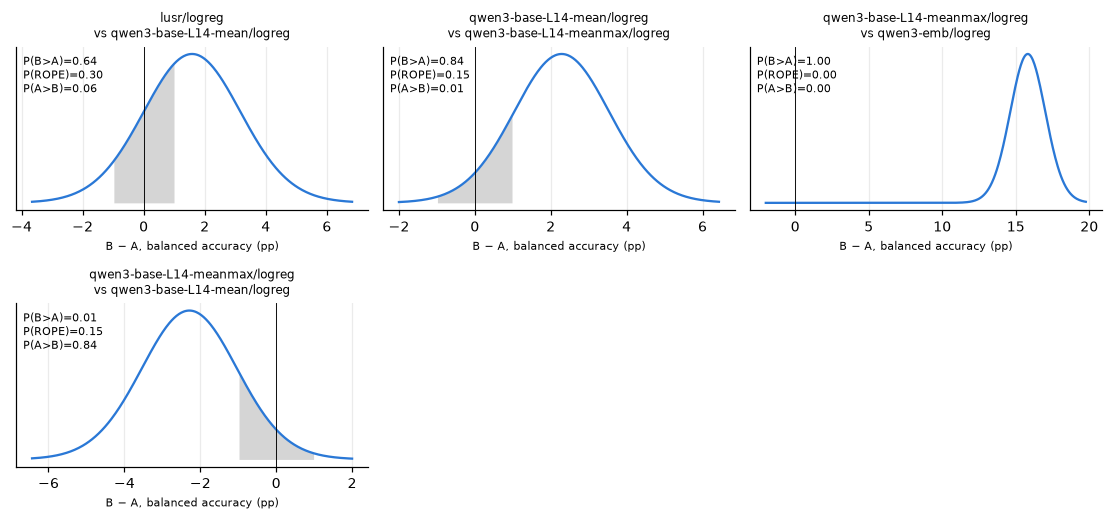

C chosen per fold: {'length/logreg': {10.0: 30, 1.0: 16, 0.1: 4}, 'qwen3-emb/logreg': {0.001: 31, 0.01: 12, 0.0001: 4, 0.1: 3}, 'lusr/logreg': {0.01: 28, 0.1: 12, 0.001: 6, 1.0: 3, 10.0: 1}, 'qwen3-base-L14-mean/logreg': {0.01: 33, 0.001: 11, 0.1: 3, 10.0: 3}, 'qwen3-base-L14-meanmax/logreg': {10.0: 22, 0.01: 14, 0.001: 8, 0.1: 4, 1.0: 2}}


In [15]:
# Quick selection: logistic regression (nested C) on each embedding, same 50 shared folds
for k, X in EMB.items():
    cv(f"{k}/logreg", X[IDX_TRAIN], "logreg")

SEL = {k: RESULTS[k] for k in ["length/logreg"] + [f"{e}/logreg" for e in EMB]}
display(A.results_table(SEL))
ranked = list(A.results_table(SEL).index)  # best first
adjacent = [(ranked[i + 1], ranked[i]) for i in range(len(ranked) - 1)]
pooling = [(f"qwen3-base-L{QWEN_BASE_LAYER}-mean/logreg", f"qwen3-base-L{QWEN_BASE_LAYER}-meanmax/logreg")]
pairs = list(dict.fromkeys(p for p in adjacent + pooling if "length/logreg" not in p))  # baseline pairs come from `baseline`
SEL_TABLE, SEL_CMPS = A.comparison_table(SEL, baseline="length/logreg", pairs=pairs)
display(SEL_TABLE)
A.plot_posteriors(SEL_CMPS[len(SEL) - 1:], path=FIG_DIR / "s5_embedding_selection_posteriors.png"); plt.show()
print("C chosen per fold:", {k: pd.Series([f["params"]["C"] for f in SEL[k]["folds"]]).value_counts().to_dict() for k in SEL})

**Findings (step 5):**
- **Style beats semantics.** LUSR (style) reaches 35.8% balanced accuracy and Qwen3-0.6B-Base layer 14 (mean pooling) reaches 34.2%. The semantic Qwen3-Embedding gets only 16.1%, barely above the length-only baseline (12.3%), even though it shares the backbone with Qwen3-Base. Embedding fine-tuning for semantic similarity throws away the authorship signal, as Rivera Soto et al. (2024) report.
- **LUSR vs Qwen3-Base:** the difference is not practically clear: P(LUSR better) = 0.64, P(ROPE) = 0.30. Both go to step 6.
- **Pooling:** mean pooling beats mean ‖ max (P = 0.84, +2.3 pp). Max pooling doubles the dimension and adds noise with only 1,700 training passages per fold.
- **Tuning:** inner CV picks C = 0.01 most often for both kept embeddings, inside the grid.
- Embedding all 2,699 passages on MPS took 33 s (LUSR) and about 2 min (Qwen3-Base), well inside the budget.

## Step 6 · Models

**Why:** the rubric asks for a log-linear model, a one-hidden-layer MLP and one more architecture. We run all of them on the two best embeddings from step 5, with the shared nested-CV protocol, so Liam's runs on token indicators and bag-of-words use exactly the same models and grids. Models 4 and 5 test whether learning the representation itself pays off.

| # | Model | Input | Search space (inner validation, nested) | Repeats |
|---|---|---|---|---|
| 1 | Multinomial logistic regression (+ StandardScaler); one-vs-rest as a cheap check | embedding | C ∈ {1e-4, 1e-3, 1e-2, 0.1, 1, 10}; OvR C = 0.01 | 10 (50 folds) |
| 2 | MLP, 1 hidden layer (ReLU, dropout), AdamW, early stopping | embedding | hidden {256, 1024} × dropout {0.2, 0.5} × lr {1e-3, 3e-4} × wd {1e-4, 1e-2} | 10 |
| 3 | Residual MLP: 2–3 pre-LayerNorm residual blocks, GELU, dropout | embedding | layers {2, 3} × hidden {256, 512} × dropout {0.3, 0.5} × lr {1e-3, 3e-4}, wd 1e-2 | 10 |
| 4 | Transformer from scratch: 2 layers, 4 heads, pre-LN, mean pooling, linear softmax | RoBERTa BPE ids (vocabulary = ids seen ≥ 2× in the training fold) | d_model {128, 256}, lr 5e-4, dropout 0.1, wd 0.01, ≤ 60 epochs, patience 8 | 1 (5 folds) |
| 5 | Fine-tuned LUSR + mean pooling + linear head (Sun et al. 2025 setup) | raw text | fixed: lr 2e-5 (head 1e-3), wd 0.01, linear warmup 10% then decay to 0, batch 16, 5 epochs (and a 10-epoch rerun); no early stopping (it would cut the schedule): the best of the 5 epoch checkpoints on inner validation is kept | 1 (5 folds) |

Models 4–5 cost minutes per fold on MPS (timed below), so they use the first CV repeat only. `compare()` pairs them with the other models on those same 5 folds. For them, the epoch is chosen on the inner validation set and that checkpoint is scored on the outer fold, without a refit.

In [16]:
# 6.1-6.3: logistic regression (+ OvR check), MLP and residual MLP on the two kept embeddings
KEEP = ["lusr", f"qwen3-base-L{QWEN_BASE_LAYER}-mean"]
for e in KEEP:
    for m in ["logreg_ovr", "mlp", "resmlp"]:
        cv(f"{e}/{m}", EMB[e][IDX_TRAIN], m)
display(A.results_table({k: v for k, v in RESULTS.items() if k.split("/")[0] in KEEP}))
for e in KEEP:
    for m in ["mlp", "resmlp"]:
        chosen = pd.DataFrame([f["params"] for f in RESULTS[f"{e}/{m}"]["folds"]])
        print(f"{e}/{m}: most frequent params", chosen.value_counts().index[0], "| median epochs",
              int(np.median([f["epochs"] for f in RESULTS[f"{e}/{m}"]["folds"]])))

lusr/logreg_ovr                    bal.acc 0.3643 ± 0.0192  (loaded, 50 folds)
lusr/mlp                           bal.acc 0.3506 ± 0.0212  (loaded, 50 folds)
lusr/resmlp                        bal.acc 0.3568 ± 0.0226  (loaded, 50 folds)
qwen3-base-L14-mean/logreg_ovr     bal.acc 0.3447 ± 0.0183  (loaded, 50 folds)
qwen3-base-L14-mean/mlp            bal.acc 0.3421 ± 0.0231  (loaded, 50 folds)
qwen3-base-L14-mean/resmlp         bal.acc 0.3460 ± 0.0237  (loaded, 50 folds)


,folds,minutes,balanced_accuracy,accuracy,macro_f1
system,,,,,
lusr/logreg_ovr,50,0.0,0.3643 ± 0.0194,0.3644 ± 0.0194,0.3534 ± 0.0202
lusr/logreg,50,0.1,0.3579 ± 0.0244,0.3579 ± 0.0245,0.3504 ± 0.0249
lusr/resmlp,50,3.9,0.3568 ± 0.0228,0.3569 ± 0.0229,0.3444 ± 0.0254
lusr/mlp,50,2.0,0.3506 ± 0.0214,0.3507 ± 0.0215,0.3406 ± 0.0212
qwen3-base-L14-mean/resmlp,50,4.6,0.3460 ± 0.0240,0.3461 ± 0.0241,0.3367 ± 0.0236
qwen3-base-L14-mean/logreg_ovr,50,0.0,0.3447 ± 0.0185,0.3448 ± 0.0186,0.3364 ± 0.0192
qwen3-base-L14-mean/mlp,50,3.0,0.3421 ± 0.0233,0.3422 ± 0.0234,0.3329 ± 0.0233
qwen3-base-L14-mean/logreg,50,0.1,0.3420 ± 0.0258,0.3421 ± 0.0259,0.3328 ± 0.0295


lusr/mlp: most frequent params (np.int64(256), np.float64(0.5), np.float64(0.001), np.float64(0.0001)) | median epochs 25
lusr/resmlp: most frequent params (np.int64(2), np.int64(256), np.float64(0.5), np.float64(0.0003), np.float64(0.01)) | median epochs 18
qwen3-base-L14-mean/mlp: most frequent params (np.int64(256), np.float64(0.5), np.float64(0.001), np.float64(0.0001)) | median epochs 24
qwen3-base-L14-mean/resmlp: most frequent params (np.int64(3), np.int64(256), np.float64(0.5), np.float64(0.0003), np.float64(0.01)) | median epochs 16


In [17]:
# 6.4-6.5: models that read the text itself (shared/text_models.py), first CV repeat only
import warnings

from shared import text_models as T

# MPS has no deterministic embedding backward; results can vary slightly between runs (seeded otherwise)
warnings.filterwarnings("ignore", message=".*does not have a deterministic implementation.*")


def cv_text(name, kind, folds=FOLDS_FT, **kw):
    """Like cv(), for text_models.run_cv_text."""
    saved = H.load_results(name.replace("/", "__") + ".json")
    if saved and not RECOMPUTE and len(saved[name]["folds"]) == len(folds):
        RESULTS[name] = saved[name]
        print(f"{name:34s} bal.acc {H.fold_scores(saved[name]).mean():.4f} (loaded, {len(folds)} folds)")
    else:
        RESULTS[name] = T.run_cv_text(d["text"], y, groups, folds, kind, name=name, **kw)
        H.save_result(RESULTS[name])
    return RESULTS[name]


print("device:", T.DEVICE, "| transformer grid:", T.TRANSFORMER_GRID, "| fixed:", T.TRANSFORMER_FIXED)
cv_text("roberta-ids/transformer", "transformer")

RUN_FINETUNE = True  # ~35 min on MPS for 5 folds x 5 epochs (Cesare chose 5 epochs over the 30-min rule)
print("fine-tuning:", T.FINETUNE_FIXED)
if RUN_FINETUNE or H.load_results("lusr-finetune__finetune.json"):
    cv_text("lusr-finetune/finetune", "finetune")

device: mps | transformer grid: {'d_model': [128, 256], 'lr': [0.0005]} | fixed: {'layers': 2, 'heads': 4, 'dropout': 0.1, 'weight_decay': 0.01, 'batch_size': 32, 'max_epochs': 60, 'patience': 8, 'min_freq': 2, 'max_len': 512, 'tokenizer': 'roberta-bpe'}
roberta-ids/transformer            bal.acc 0.2158 (loaded, 5 folds)
fine-tuning: {'model_id': 'rrivera1849/LUSR', 'lr': 2e-05, 'head_lr': 0.001, 'weight_decay': 0.01, 'epochs': 5, 'train_layers': None, 'head_dropout': 0.0, 'batch_size': 16, 'warmup': 0.1, 'max_len': 512}
lusr-finetune/finetune             bal.acc 0.3380 (loaded, 5 folds)


lusr-finetune-10ep/finetune        bal.acc 0.3352 (loaded, 5 folds)


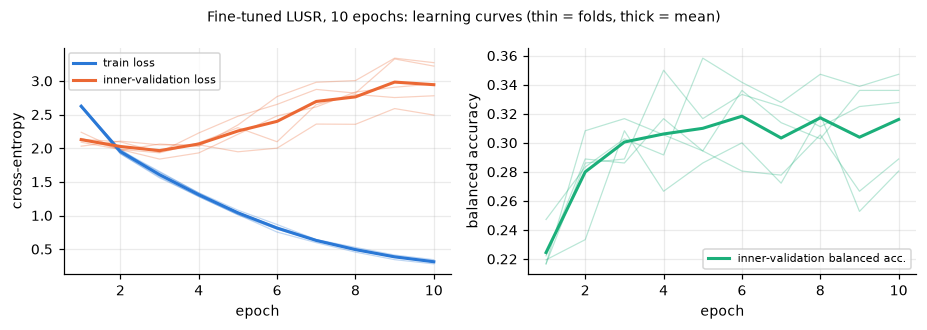

epoch,1,2,3,4,5,6,7,8,9,10
train_loss,2.6240,1.9505,1.6071,1.3092,1.0402,0.8133,0.6291,0.4935,0.3854,0.3128
val_loss,2.1276,2.0260,1.9646,2.0631,2.2563,2.3997,2.6954,2.7633,2.9832,2.9445
val_bal_acc,0.2244,0.2800,0.3006,0.3061,0.3100,0.3183,0.3033,0.3172,0.3039,0.3161
fold,2.0000,2.0000,2.0000,2.0000,2.0000,2.0000,2.0000,2.0000,2.0000,2.0000


best epoch per fold: [4, 4, 5, 8, 6]


,A,B,folds,mean B−A,P(A>B),P(ROPE),P(B>A)
0,lusr-finetune/finetune,lusr-finetune-10ep/finetune,5,-0.0028,0.3492,0.3990,0.2519
1,lusr/logreg,lusr-finetune-10ep/finetune,5,-0.0319,0.7786,0.1319,0.0896


In [18]:
# 6.5b Fine-tuned LUSR trained longer: at 5 epochs the best epoch was the last one in 4 of 5 folds.
#      Same setup, 10 epochs (the LR schedule stretches to 10 epochs); per-epoch curves are logged.
cv_text("lusr-finetune-10ep/finetune", "finetune", epochs=10)
FT10 = RESULTS["lusr-finetune-10ep/finetune"]
curves = pd.DataFrame([{**h, "fold": f["fold"]} for f in FT10["folds"] for h in f["history"]])
mean = curves.groupby("epoch").mean()
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3))
for k, g in curves.groupby("fold"):
    axes[0].plot(g.epoch, g.train_loss, color="#2a78d6", alpha=0.3, lw=0.8)
    axes[0].plot(g.epoch, g.val_loss, color="#eb6834", alpha=0.3, lw=0.8)
    axes[1].plot(g.epoch, g.val_bal_acc, color="#1baf7a", alpha=0.3, lw=0.8)
axes[0].plot(mean.index, mean.train_loss, color="#2a78d6", lw=2, label="train loss")
axes[0].plot(mean.index, mean.val_loss, color="#eb6834", lw=2, label="inner-validation loss")
axes[1].plot(mean.index, mean.val_bal_acc, color="#1baf7a", lw=2, label="inner-validation balanced acc.")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy"); axes[0].legend(fontsize=7)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("balanced accuracy"); axes[1].legend(fontsize=7)
fig.suptitle("Fine-tuned LUSR, 10 epochs: learning curves (thin = folds, thick = mean)", fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "s6_finetune_curves.png", dpi=200); plt.show()
display(mean.round(4).T)
print("best epoch per fold:", [f["epochs"] for f in FT10["folds"]])
display(A.comparison_table(RESULTS, pairs=[("lusr-finetune/finetune", "lusr-finetune-10ep/finetune"),
                                           ("lusr/logreg", "lusr-finetune-10ep/finetune")])[0])

In [19]:
# 6.5c Partial fine-tuning: full fine-tuning overfits (validation loss lowest at epoch 3), so train fewer weights.
#      Freeze the embeddings and all but the top k of 12 layers (frozen layers in eval mode, no dropout),
#      dropout 0.1 before the head, lr 5e-5 for the trained layers, 6 epochs. About 15 min per system on MPS.
for k in (2, 4):
    cv_text(f"lusr-finetune-top{k}/finetune", "finetune", train_layers=k, head_dropout=0.1, lr=5e-5, epochs=6)
print("best epoch per fold:", {k: [f["epochs"] for f in RESULTS[f"lusr-finetune-top{k}/finetune"]["folds"]] for k in (2, 4)})
display(A.comparison_table(RESULTS, pairs=[("lusr-finetune/finetune", "lusr-finetune-top2/finetune"),
                                           ("lusr-finetune/finetune", "lusr-finetune-top4/finetune"),
                                           ("lusr/logreg", "lusr-finetune-top2/finetune"),
                                           ("lusr/logreg", "lusr-finetune-top4/finetune")])[0])

lusr-finetune-top2/finetune        bal.acc 0.3477 (loaded, 5 folds)
lusr-finetune-top4/finetune        bal.acc 0.3584 (loaded, 5 folds)
best epoch per fold: {2: [6, 4, 6, 5, 5], 4: [4, 6, 6, 6, 5]}


,A,B,folds,mean B−A,P(A>B),P(ROPE),P(B>A)
0,lusr-finetune/finetune,lusr-finetune-top2/finetune,5,0.0097,0.1266,0.3804,0.4930
1,lusr-finetune/finetune,lusr-finetune-top4/finetune,5,0.0204,0.0816,0.2144,0.7041
2,lusr/logreg,lusr-finetune-top2/finetune,5,-0.0194,0.6306,0.2057,0.1637
3,lusr/logreg,lusr-finetune-top4/finetune,5,-0.0088,0.4830,0.2621,0.2549


**Findings (6.5c):** training fewer weights helps. Top-4 layers (28M of 125M parameters trained) reaches 35.8% balanced accuracy and top-2 (14M) reaches 34.8%, against 33.8% for full fine-tuning (P(top-4 better) = 0.70). Validation loss no longer rises: it flattens at about 1.73 instead of bottoming at 1.96 and climbing. Top-4 is level with frozen LUSR + logistic regression on the same 5 folds (36.7%; P(LR better) = 0.48, P(ROPE) = 0.26), so partial fine-tuning matches the frozen baseline but does not yet beat it. The best epoch is mostly 5 or 6, the last ones, so a slightly longer run could still gain a little.

**Findings (step 6):**
- **The three rubric architectures tie on LUSR:** logistic regression 35.8%, MLP 35.1%, residual MLP 35.7% balanced accuracy (50 folds). Against logistic regression: MLP P(ROPE) = 0.50, P(LR better) = 0.41; residual MLP P(ROPE) = 0.62. Qwen3-Base shows the same pattern (34.2–34.6%). The frozen embeddings are close to linearly separable at this data size, and extra layers mainly overfit: inner CV picks the strongest dropout (0.5) and the smallest width (256) in most folds.
- **One-vs-rest logistic regression** (the cheap check, C fixed at 0.01) is nominally best at 36.4%, but it is inside the ROPE against multinomial LR (P(ROPE) = 0.61).
- **Transformer from scratch:** 21.6% ± 1.8 (5 folds, 7 min on MPS; d = 256 chosen in every fold, best epoch 7–15). It learns something (length alone gives 12%), but with about 1,700 passages per fold it cannot learn the representation that pretrained encoders bring.
- **Fine-tuned LUSR:** 33.8% ± 3.8 with 5 epochs (28 min) and 33.5% ± 3.6 with 10 epochs (55 min). Both are worse than the frozen LUSR embedding + LR on the same 5 folds (−2.9 and −3.2 pp; P(frozen better) = 0.82 and 0.78), and 10 epochs are practically the same as 5 (P(ROPE) = 0.40).
- **Training longer does not help** (`figures/s6_finetune_curves.png`). Inner-validation loss is lowest at epoch 3 (1.96) and then rises to 2.94, while training loss falls to 0.31: the model memorises the 1,400 inner-training passages. Validation balanced accuracy plateaus at about 31% from epoch 4. At 5 epochs the best epoch was the last one because the learning rate decays to 0 at the end of the schedule, not because training was cut short. Fine-tuning is limited by data, not epochs.

## Step 7 · Evaluation and analysis

**Why:** this compares every neural-track system on the shared folds, tests the differences with the Bayesian correlated t-test (ROPE = 1 pp), and looks at where the errors come from (family, class, length). The held-out test split is used once, at the end, for a set of systems fixed in advance.

,folds,minutes,balanced_accuracy,accuracy,macro_f1
system,,,,,
lusr/logreg_ovr,50,0.0,0.3643 ± 0.0194,0.3644 ± 0.0194,0.3534 ± 0.0202
lusr-finetune-top4/finetune,5,16.1,0.3584 ± 0.0249,0.3585 ± 0.0248,0.3402 ± 0.0262
lusr/logreg,50,0.1,0.3579 ± 0.0244,0.3579 ± 0.0245,0.3504 ± 0.0249
lusr/resmlp,50,3.9,0.3568 ± 0.0228,0.3569 ± 0.0229,0.3444 ± 0.0254
lusr/mlp,50,2.0,0.3506 ± 0.0214,0.3507 ± 0.0215,0.3406 ± 0.0212
lusr-finetune-top2/finetune,5,13.1,0.3477 ± 0.0199,0.3478 ± 0.0199,0.3341 ± 0.0180
qwen3-base-L14-mean/resmlp,50,4.6,0.3460 ± 0.0240,0.3461 ± 0.0241,0.3367 ± 0.0236
qwen3-base-L14-mean/logreg_ovr,50,0.0,0.3447 ± 0.0185,0.3448 ± 0.0186,0.3364 ± 0.0192
qwen3-base-L14-mean/mlp,50,3.0,0.3421 ± 0.0233,0.3422 ± 0.0234,0.3329 ± 0.0233


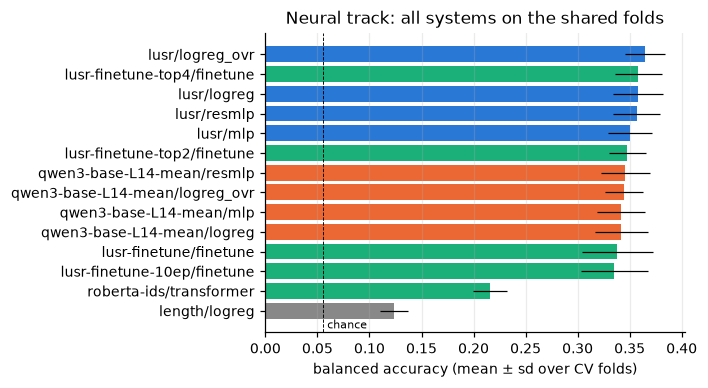

In [20]:
# 7.1 Results table (mean ± sd over folds) for the kept embeddings, the text models and the length baseline
SYSTEMS = {k: v for k, v in RESULTS.items() if k.split("/")[0] in KEEP + ["roberta-ids", "lusr-finetune", "lusr-finetune-10ep", "lusr-finetune-top2", "lusr-finetune-top4", "length"]}
RES_TABLE = A.results_table(SYSTEMS)
display(RES_TABLE)
RES_TABLE.to_csv(FIG_DIR / "s7_results_table.csv")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
names = list(RES_TABLE.index)[::-1]
mu = [H.fold_scores(SYSTEMS[n]).mean() for n in names]
sd = [H.fold_scores(SYSTEMS[n]).std() for n in names]
col = ["#2a78d6" if n.startswith("lusr/") else "#eb6834" if n.startswith("qwen3") else "#1baf7a" if "/" in n and not n.startswith("length") else "#888888" for n in names]
ax.barh(names, mu, xerr=sd, color=col, error_kw={"lw": 0.8})
ax.axvline(1 / 18, color="black", lw=0.6, ls="--"); ax.text(1 / 18, -0.9, " chance", fontsize=7)
ax.set_xlabel("balanced accuracy (mean ± sd over CV folds)")
ax.set_title("Neural track: all systems on the shared folds"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "s7_results.png", dpi=200); plt.show()

baseline: lusr/logreg


,A,B,folds,mean B−A,P(A>B),P(ROPE),P(B>A)
0,lusr/logreg,qwen3-base-L14-mean/logreg,50,-0.0159,0.6418,0.3015,0.0567
1,lusr/logreg,lusr/logreg_ovr,50,0.0065,0.0390,0.6101,0.3509
2,lusr/logreg,lusr/mlp,50,-0.0072,0.4135,0.4980,0.0885
3,lusr/logreg,lusr/resmlp,50,-0.0010,0.2119,0.6249,0.1632
4,lusr/logreg,qwen3-base-L14-mean/logreg_ovr,50,-0.0132,0.5836,0.3519,0.0645
5,lusr/logreg,qwen3-base-L14-mean/mlp,50,-0.0158,0.6568,0.3053,0.0379
6,lusr/logreg,qwen3-base-L14-mean/resmlp,50,-0.0119,0.5472,0.3683,0.0845
7,lusr/logreg,roberta-ids/transformer,5,-0.1513,0.9984,0.0006,0.0010
8,lusr/logreg,lusr-finetune/finetune,5,-0.0292,0.8196,0.1290,0.0514
9,lusr/logreg,lusr-finetune-10ep/finetune,5,-0.0319,0.7786,0.1319,0.0896


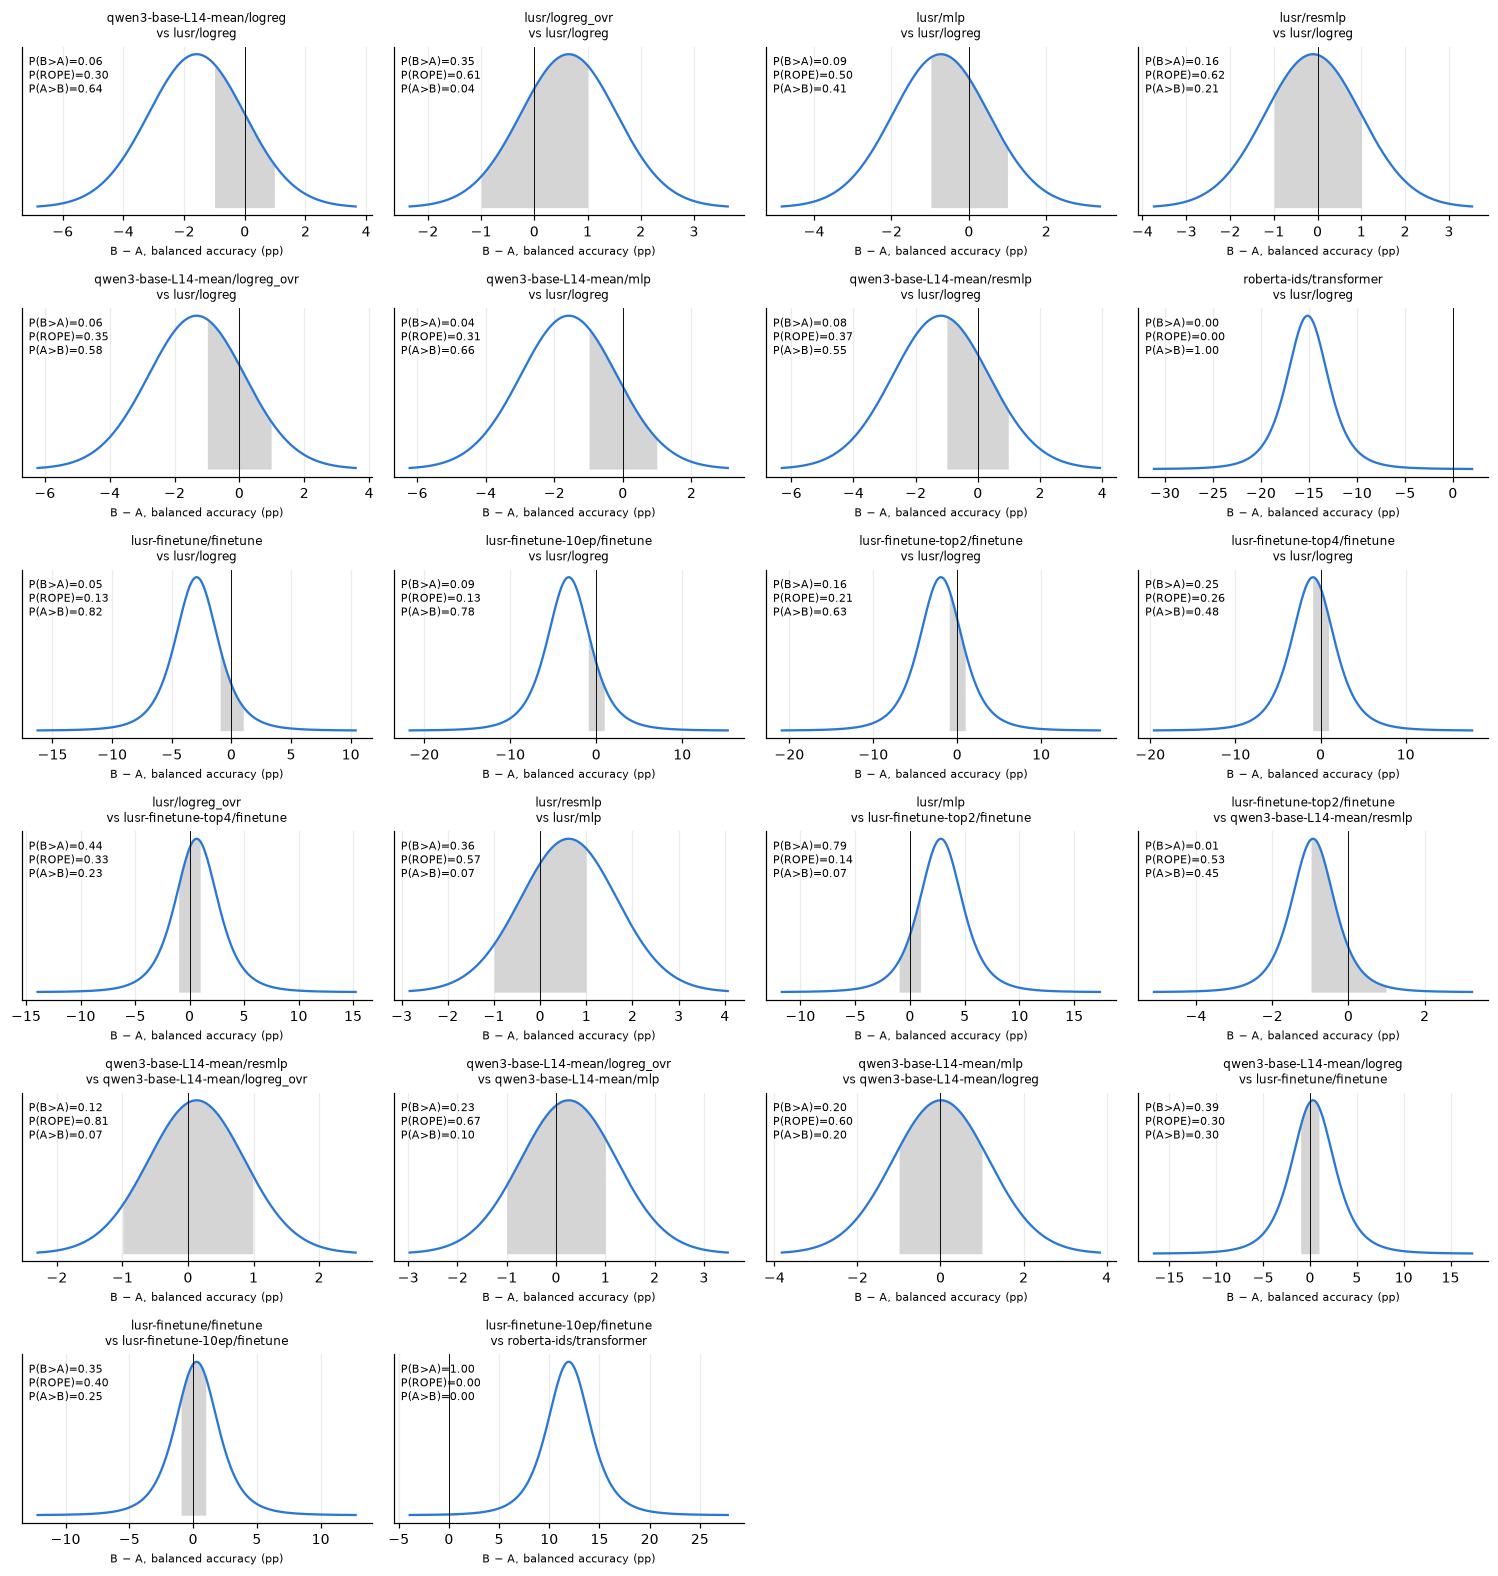

In [21]:
# 7.2 Bayesian correlated t-tests: every system vs the best logistic-regression baseline, and adjacent systems
CMP_SYSTEMS = {k: v for k, v in SYSTEMS.items() if not k.startswith("length")}
ranked = [n for n in RES_TABLE.index if n in CMP_SYSTEMS]
BASE = next(n for n in ranked if n.endswith("/logreg"))
adjacent = [(ranked[i + 1], ranked[i]) for i in range(len(ranked) - 1)]
pairs = list(dict.fromkeys(p for p in adjacent if BASE not in p))
CMP_TABLE, CMPS = A.comparison_table(CMP_SYSTEMS, baseline=BASE, pairs=pairs)
print("baseline:", BASE)
display(CMP_TABLE)
CMP_TABLE.to_csv(FIG_DIR / "s7_bayes_table.csv")
A.plot_posteriors(CMPS, ncols=4, path=FIG_DIR / "s7_posteriors.png"); plt.show()

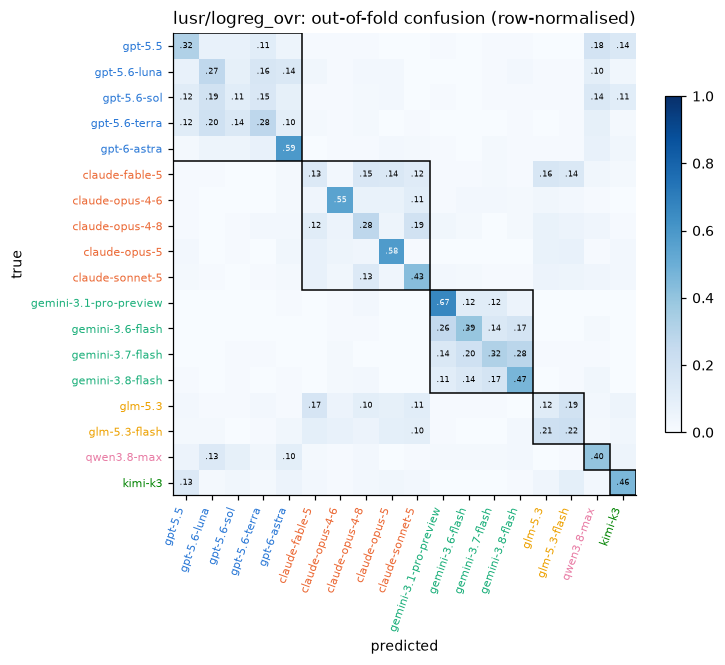

,model_accuracy,family_accuracy,errors,within_family_share_of_errors,within_family_share_if_uniform
lusr/logreg_ovr,0.365,0.697,1371.0,0.522,0.176
lusr-finetune-top4/finetune,0.358,0.716,1385.0,0.557,0.176
lusr/logreg,0.367,0.695,1366.0,0.518,0.176
lusr/resmlp,0.369,0.709,1362.0,0.539,0.176
lusr/mlp,0.376,0.706,1347.0,0.529,0.176
lusr-finetune-top2/finetune,0.348,0.708,1408.0,0.553,0.176
qwen3-base-L14-mean/resmlp,0.357,0.677,1388.0,0.498,0.176
qwen3-base-L14-mean/logreg_ovr,0.351,0.647,1401.0,0.455,0.176
qwen3-base-L14-mean/mlp,0.344,0.658,1417.0,0.478,0.176
qwen3-base-L14-mean/logreg,0.341,0.641,1422.0,0.454,0.176


In [22]:
# 7.3 Errors by family: confusion matrix of the best system (out-of-fold, CV repeat 0) + within-family share
BEST = ranked[0]
A.plot_confusion(y, RESULTS[BEST]["oof_pred"], DATA, title=f"{BEST}: out-of-fold confusion (row-normalised)",
                 path=FIG_DIR / "s7_confusion.png"); plt.show()
FAM_ERR = pd.DataFrame({n: A.family_errors(y, RESULTS[n]["oof_pred"], DATA) for n in ranked}).T
display(FAM_ERR.round(3))

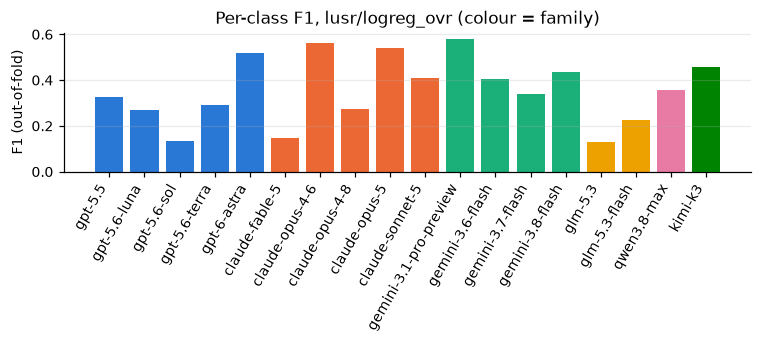

,gpt-5.5,gpt-5.6-luna,gpt-5.6-sol,gpt-5.6-terra,gpt-6-astra,claude-fable-5,claude-opus-4-6,claude-opus-4-8,claude-opus-5,claude-sonnet-5,gemini-3.1-pro-preview,gemini-3.6-flash,gemini-3.7-flash,gemini-3.8-flash,glm-5.3,glm-5.3-flash,qwen3.8-max,kimi-k3
f1,0.325,0.27,0.134,0.291,0.516,0.148,0.562,0.274,0.538,0.408,0.578,0.403,0.339,0.434,0.131,0.227,0.357,0.458
recall,0.317,0.267,0.108,0.275,0.592,0.134,0.55,0.275,0.583,0.433,0.667,0.392,0.317,0.467,0.117,0.217,0.4,0.458
family,GPT,GPT,GPT,GPT,GPT,Claude,Claude,Claude,Claude,Claude,Gemini,Gemini,Gemini,Gemini,GLM,GLM,Qwen,Kimi


,lusr/logreg_ovr,lusr-finetune-top4/finetune,lusr/logreg,lusr/resmlp,n
"(0, 75]",0.286,0.284,0.293,0.299,730
"(75, 100]",0.387,0.349,0.387,0.372,341
"(100, 125]",0.355,0.351,0.355,0.374,262
"(125, 150]",0.358,0.394,0.349,0.353,218
"(150, 1000]",0.454,0.444,0.457,0.456,608


In [23]:
# 7.4 Per-class F1 and accuracy by length bin (best system)
PCF = A.per_class_f1(y, RESULTS[BEST]["oof_pred"], DATA)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(PCF.index, PCF["f1"], color=[FAMILY_COLOR[f] for f in PCF["family"]])
ax.set_xticks(range(len(PCF)), PCF.index, rotation=60, ha="right"); ax.set_ylabel("F1 (out-of-fold)")
ax.set_title(f"Per-class F1, {BEST} (colour = family)"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "s7_per_class_f1.png", dpi=200); plt.show()
display(PCF.round(3).T)
n_words = d["text"].str.split().str.len()
display(pd.concat({n: A.accuracy_by_length(y, RESULTS[n]["oof_pred"], n_words)["accuracy"] for n in ranked[:4]}, axis=1)
        .assign(n=A.accuracy_by_length(y, RESULTS[BEST]["oof_pred"], n_words)["n"]).round(3))

In [24]:
# 7.5 Ten misclassified passages (most confident errors of the best system)
MIS = A.misclassified(d, y, RESULTS[BEST]["oof_pred"], DATA, n=10, proba=RESULTS[BEST]["oof_proba"])
with pd.option_context("display.max_colwidth", 400):
    display(MIS[["true", "pred", "confidence", "text"]])

,true,pred,confidence,text
981,gpt-5.5,gemini-3.1-pro-preview,0.831,"Imagine a friend claims they know the secret code to open a locked museum door, but they do not want to reveal it. You stand outside while they enter through one of two identical corridors behind the door. Then you randomly shout, “Come out through the left corridor!” or “Come out through the right!” If they truly know the code, they can always unlock the connecting door and appear where reque..."
1876,glm-5.3,claude-opus-5,0.731,"From the edge of the solar system, some four billion miles away, our world is a single pale pixel, a mote of dust suspended in a sunbeam. On that dot, every war was fought, every song was sung, every love affair began and ended; every saint and tyrant, every ancestor you never met, lived out their days. The oceans that cradle life, the civilizations that rose and fell, all compressed into less..."
620,glm-5.3-flash,claude-opus-5,0.696,"Deep in the body's crowded neighborhoods, an old cell closes its shop. The looms of division, once rhythmic as heartbeats, fall silent; the spindle threads snap, the copies stop coming, and the door is locked from the inside by p53's cold key. Telomeres, shortened like candle wicks burned to stubs, long ago gave the order: no more doubling, no more nights of quiet renewal. But the cell does no..."
293,gemini-3.7-flash,gemini-3.1-pro-preview,0.696,"Gödel showed that any logical system capable of basic arithmetic contains true statements that cannot be proven using its own rules. Essentially, truth is broader than proof. Therefore, no mathematical framework can ever be entirely complete or capable of independently confirming its own total consistency."
1861,claude-opus-4-6,claude-opus-5,0.684,"The audience can see the letter on the table — they have watched Lady Harwick place it there with trembling, deliberate hands, the letter that confesses everything, that names her lover, that begs forgiveness in language so raw it will unmake a marriage of twenty years — and now they hear Edmund's boots in the corridor, his cheerful whistling, the sound of a man who believes he is coming home ..."
368,claude-opus-4-6,claude-opus-5,0.675,"You believed me, didn't you — leaned in closer when I whispered that she was the villain, that I was merely the wounded party stumbling through a story not of my making. That's the seduction: I offer you my voice, trembling and intimate, and you mistake proximity for honesty. I rearrange the furniture of what happened so carefully that you never notice the missing chair, the bloodstain painted..."
1392,claude-fable-5,gemini-3.1-pro-preview,0.658,"Dark matter forms an invisible scaffolding upon which the visible universe is built. Though it emits no light and eludes direct detection, its gravitational pull sculpts vast cosmic webs, threading galaxies along filaments like beads on unseen strings. Without this hidden framework, galaxies would fly apart and stars could never have clustered into the luminous structures we observe. Everythin..."
2066,glm-5.3,claude-opus-4-6,0.655,"Hundreds of miles beneath your feet, where pressure tops two hundred thousand atmospheres, a humble blue crystal guards a secret that rewrote Earth's story: ringwoodite, an olivine polymorph that drinks water directly into its crystal lattice. In 2014, a Brazilian diamond ferried a single grain of it up to the surface, revealing hydroxyl ions bound within — proof that the mantle's transition z..."
1256,gemini-3.6-flash,gemini-3.7-flash,0.635,"Deep within the sun’s boiling cauldron, violent coronal mass ejections unleash a tempestuous torrent of solar wind, hurling vast clouds of energetic electrons and protons across ninety-three million miles of frigid, empty space toward Earth. Traveling at hypersonic velocities, this invisible celestial tide collides head-on with our planet’s invisible defensive bulwark, the magnetosphere. The b..."
186,gpt-5.6-sol,kimi-k3,0.618,"Along the Mandelbrot set’s black shore, infi

In [25]:
# 7.6 The single held-out test evaluation (systems fixed in advance: the 3 rubric architectures on the
#     best embedding, plus the overall CV-best system if it is a text model). Test SE is about 2 pp.
TEST = {}
best_emb = BASE.split("/")[0]
for m in ["logreg", "mlp", "resmlp"]:
    TEST[f"{best_emb}/{m}"] = H.final_test(EMB[best_emb][IDX_TRAIN], y, groups, EMB[best_emb][IDX_TEST], y_test, m)
if RESULTS[BEST]["model"] in ("transformer", "finetune"):
    TEST[BEST] = T.final_test_text(d["text"], y, groups, test_split_df["text"], y_test, RESULTS[BEST]["model"],
                                  **RESULTS[BEST].get("fixed", {}))
TEST_TABLE = pd.DataFrame({n: {k: r[k] for k in ["balanced_accuracy", "accuracy", "macro_f1"]} for n, r in TEST.items()}).T
TEST_TABLE["CV balanced_accuracy"] = [H.fold_scores(RESULTS[n]).mean() for n in TEST_TABLE.index]
display(TEST_TABLE.round(4))
TEST_TABLE.to_csv(FIG_DIR / "s7_test_table.csv")
best_test = max(TEST, key=lambda n: TEST[n]["balanced_accuracy"])
display(A.family_errors(y_test, TEST[best_test]["pred"], DATA).round(3).to_frame(f"test: {best_test}").T)

,balanced_accuracy,accuracy,macro_f1,CV balanced_accuracy
lusr/logreg,0.3407,0.3407,0.3327,0.3579
lusr/mlp,0.3537,0.3537,0.3423,0.3506
lusr/resmlp,0.3593,0.3593,0.3513,0.3568


,model_accuracy,family_accuracy,errors,within_family_share_of_errors,within_family_share_if_uniform
test: lusr/resmlp,0.359,0.7,346.0,0.532,0.176


**Findings (step 7):**
- **Results:** the best system, LUSR + logistic regression, reaches 35.8–36.4% balanced accuracy, 6.5× chance (5.6%) and 3× the length-only baseline. Among the 8 embedding systems, no pair differs by more than the ROPE with high probability: the representation choice (LUSR vs Qwen3-Base, about +1.5 pp, P = 0.64) matters more than the architecture.
- **Errors concentrate within families.** The family is right about 70% of the time even when the model is wrong: 52% of errors stay inside the true family, against 17.6% if errors were spread uniformly. The hardest blocks are version neighbours: GPT-5.6 luna/sol/terra, and Gemini 3.6/3.7/3.8-flash. The main cross-family confusion is **GLM → Claude** (glm-5.3 is predicted as a Claude model in about 40% of cases), which matches step 1: both families use straight quotes and spaced em dashes. GPT-5.5 also leaks to Qwen and Kimi.
- **Per class:** best gemini-3.1-pro-preview (F1 0.58), claude-opus-4-6 (0.56), claude-opus-5 (0.54), gpt-6-astra (0.52); worst glm-5.3 (0.13), gpt-5.6-sol (0.13), claude-fable-5 (0.15).
- **Length:** accuracy rises from 29% on passages under 75 words to 46% above 150 words, for every system. Short passages carry too little evidence, and they make up a third of the data.
- **Ten misclassified passages (inspected):** (i) four are lyrical, em-dash-heavy prose from GLM or Claude Opus 4.6 predicted as another Claude model. The style is genuinely shared, and the typography (spaced "—", straight apostrophes) is identical; (ii) three are version neighbours within a family (Opus 4.6 → Opus 5 twice, Gemini 3.6 → 3.7); (iii) three are short (45–70 words) expository passages with almost no typographic cues, where the model falls back on topic-like content. GPT-5.6-sol → Kimi is an example: an unspaced em dash and curly quotes are the only cues. None looks mislabelled.
- **Held-out test (used once):** LUSR + LR 34.1%, MLP 35.4%, residual MLP 35.9%. All are within the test set's ±2 pp standard error of their CV estimates (35.8 / 35.1 / 35.7%), so CV was not optimistic. On test, 53% of errors are again within the family.
- **Do models 4 and 5 justify their cost?** No, not on this data. The from-scratch transformer costs 7 min for 5 folds and is clearly worse than every frozen-embedding system (−15 pp vs LUSR + LR, P(LR better) > 0.99). Fine-tuning LUSR costs 28 min (5 epochs) or 55 min (10 epochs) for 5 folds, 400–800× the LR's 4 s for 50 folds, and still ends below the frozen embedding with LR (P = 0.82 and 0.78), with a fold spread about 1.5× wider. The learning curves show overfitting from epoch 3, so more epochs would not change this. The MLPs cost 2–5 min for 50 folds and are practically equivalent to LR. On 2,159 passages, a frozen style embedding with a linear model is the best cost-accuracy trade-off. Fine-tuning is the option most likely to improve with more *data* (Sun et al. 2025 used far larger training sets), not with more epochs.

## Step 8 · Hand-off to Liam

Everything Liam needs is in `shared/` (see `shared/README.md`): `data.py` (split, labels, families), `eval_harness.py` (folds, models, grids, nested CV, Bayesian test, `final_test`), `analysis.py` (the tables and figures of step 7), `text_models.py` (models 4–5), `folds.json`, and `results/` (every CV result above, so his runs can be compared directly with `H.compare` or `A.comparison_table`).

## Step 9 · Slide material

**1. Data and metrics** (`part1/figures/s1_typography_by_model.png`)
- 2,699 passages, 18 LLMs from 6 families, 149–150 per class. Every prompt is answered by all models; Kazik's split is grouped by prompt (2,159 train / 540 test), because Kaggle's test prompts are unseen.
- Metric: balanced accuracy (the Kaggle metric). Stratified 5-fold CV grouped by prompt, repeated 10×, with nested tuning; Bayesian correlated t-test with ROPE = 1 pp.
- No markdown or newlines at all, but typography separates families: GPT uses curly quotes, Claude and GLM straight quotes and many em dashes, Gemini almost no em dashes. Length alone gives only 12%.

**2. Features** (`part1/figures/s5_embedding_selection_posteriors.png`)
- Neural embeddings from frozen pretrained encoders, mean-pooled per passage, with NFC normalisation only (punctuation and casing are cues).
- The style embedder LUSR (35.8%) and Qwen3-0.6B-Base layer-14 hidden states (34.2%) beat the semantic Qwen3-Embedding (16.1%), even though it shares Qwen3-Base's backbone.
- Mean pooling beats mean ‖ max pooling (+2.3 pp, P = 0.84). Embedding all passages takes under 2 min on a laptop GPU (MPS).

**3. Architectures** (`part1/figures/s7_results.png`)
- Log-linear: multinomial logistic regression; MLP with one hidden layer (ReLU, dropout); residual MLP (2–3 pre-LayerNorm blocks): the same models and grids as the other representations, from `shared/eval_harness.py`.
- A 2-layer transformer trained from scratch on RoBERTa-BPE ids, with a vocabulary built from the training fold only.
- LUSR fine-tuned end to end with a linear head (the Sun et al. 2025 setup), 5 and 10 epochs, best epoch chosen on inner validation (learning curves: `part1/figures/s6_finetune_curves.png`).

**4. Results** (`part1/figures/s7_posteriors.png`)
- Best: LUSR + logistic regression, 35.8% CV (36.4% one-vs-rest), 34.1–35.9% on the held-out test for the three architectures: 6.5× chance.
- LR, MLP and residual MLP are practically equivalent (P(ROPE) 0.50–0.62): the representation matters more than the architecture.
- The transformer from scratch (21.6%) and fine-tuning (33.8% at 5 epochs, 33.5% at 10; up to 55 min) do not justify their cost on 2,159 passages; fine-tuning overfits from epoch 3.

**5. Extra: where the errors are** (`part1/figures/s7_confusion.png`)
- The family is right about 70% of the time; 52% of model errors stay within the family (17.6% if errors were spread uniformly).
- The hardest cases are version neighbours (GPT-5.6 luna/sol/terra, Gemini 3.6/3.7/3.8-flash) and GLM → Claude, which share typography.
- Accuracy rises from 29% (< 75 words) to 46% (> 150 words). Possible confound: watermarking of Claude and Gemini sampling.

---
# Checklist sections 3–6: summary of the neural track

The course template's questions, answered with the results above (steps 5–7). Liam's token-indicator and bag-of-words results go through the same shared harness and can be added to these tables.

## 3. Document representations (features)

**What they ask:** think about how to turn documents into features. The tutorial used token occurrences (indicators) and frequencies (bag-of-words). Can we think of other ways?

**Rubric (checklist):** compare **the two representation spaces from the tutorial (token indicators and bag-of-words) plus one more of our choice**.

**Oral-assessment points** (slide: _features_):
- What does each representation capture, and what does it throw away (order, length, frequency)?
- Candidates for the third representation: TF-IDF, character n-grams, word n-grams, stylometric features (sentence length, punctuation rates, markdown usage), or combinations. Why this one for _LLM authorship_?
- Dimensionality / sparsity, and how the choice interacts with the classifier.

Helpers: `part1.clslib.TokenIndicator` (indicator encoder); bag-of-words and the third encoder are ours to write as `part1.clslib.Encoder` subclasses.

In [26]:
# Our third representation: frozen neural embeddings (step 5). One row per embedding, logistic regression on the shared folds.
REPR = pd.DataFrame({e: {"dim": EMB[e].shape[1], "kept": e in KEEP,
                         "LR balanced acc.": H.fold_scores(RESULTS[f"{e}/logreg"]).mean()} for e in EMB}).T
display(REPR.sort_values("LR balanced acc.", ascending=False))

,dim,kept,LR balanced acc.
lusr,768,True,0.357856
qwen3-base-L14-mean,1024,True,0.341993
qwen3-base-L14-meanmax,2048,False,0.319112
qwen3-emb,1024,False,0.16094


### Reflections — Step 3

- **Third representation: frozen neural embeddings,** one vector per passage (mean-pooled token states). Unlike indicators and bag-of-words, they see context and word order inside the encoder, are dense (768–1,024 dimensions instead of a 10k+ sparse vocabulary), and bring knowledge from pretraining that 2,159 passages cannot provide.
- **The choice of embedder matters more than anything downstream:** style (LUSR, 35.8%) and raw LM hidden states (Qwen3-Base, 34.2%) carry authorship; a semantic embedder (Qwen3-Embedding, 16.1%) mostly throws it away, because it is trained to map paraphrases together, and paraphrases are exactly how LLMs differ.
- **What they lose:** exact typography. A curly vs a straight quote is a different token, but after mean pooling it is one small contribution among about 150 tokens. Bag-of-words with punctuation tokens keeps this explicit, so Liam's representations may beat ours on the typographic families (GPT vs Claude/GLM) and lose on the within-family style.
- **Open question for the TA:** is mean pooling the right inductive bias, or would a learned attention pooling over frozen states help?

## 4. Architectures

**What they ask:** the tutorial used logistic regression (log-linear) and a shallow neural network. Experiment with different architectures and their hyperparameters (e.g. more layers, different activation functions, dropout rates).

**Rubric (checklist):** compare **log-linear, single-hidden-layer MLP, plus one more architecture of our choice** (e.g. a modification of the MLP).

**Oral-assessment points** (slide: _architectures_):
- What does the MLP add over the log-linear model, and does this dataset size (~2.7k docs, ~18 classes) support it?
- Why our third architecture, and what hypothesis does it test?
- Which hyperparameters did we tune, how (on what data, to avoid tuning on the evaluation folds), and why those values?

Helpers: `part1.loglin.fit`, `part1.smlp.SparseMLP`, `part1.smlp.train_neural_network_model`, `part1.experiment.cross_validation_experiment(..., model_option="logistic" | "mlp")`.

In [27]:
# Architectures and search spaces (shared/eval_harness.py and shared/text_models.py; step 6)
display(pd.DataFrame({m: {"grid": H.MODELS[m].grid, "grid points": len(H.MODELS[m].params)} for m in ["logreg", "logreg_ovr", "mlp", "resmlp"]}).T)
print("transformer:", T.TRANSFORMER_GRID, T.TRANSFORMER_FIXED)
print("fine-tuning:", {**T.FINETUNE_FIXED, "epochs": "5 and 10"})
print(H.ResMLP(1024, 18, hidden=256, dropout=0.5, layers=2))

,grid,grid points
logreg,"{'C': ['0.0001', '0.001', '0.01', '0.1', '1.0'...",6
logreg_ovr,{'C': ['0.01']},1
mlp,"{'hidden': [256, 1024], 'dropout': ['0.2', '0....",16
resmlp,"{'layers': [2, 3], 'hidden': [256, 512], 'drop...",16


transformer: {'d_model': [128, 256], 'lr': [0.0005]} {'layers': 2, 'heads': 4, 'dropout': 0.1, 'weight_decay': 0.01, 'batch_size': 32, 'max_epochs': 60, 'patience': 8, 'min_freq': 2, 'max_len': 512, 'tokenizer': 'roberta-bpe'}
fine-tuning: {'model_id': 'rrivera1849/LUSR', 'lr': 2e-05, 'head_lr': 0.001, 'weight_decay': 0.01, 'epochs': '5 and 10', 'train_layers': None, 'head_dropout': 0.0, 'batch_size': 16, 'warmup': 0.1, 'max_len': 512}
ResMLP(
  (inp): Sequential(
    (0): Dropout(p=0.25, inplace=False)
    (1): Linear(in_features=1024, out_features=256, bias=True)
  )
  (blocks): Sequential(
    (0): ResBlock(
      (f): Sequential(
        (0): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
        (1): Linear(in_features=256, out_features=256, bias=True)
        (2): GELU(approximate='none')
        (3): Dropout(p=0.5, inplace=False)
        (4): Linear(in_features=256, out_features=256, bias=True)
      )
    )
    (1): ResBlock(
      (f): Sequential(
        (0)

### Reflections — Step 4

- **Log-linear vs MLP vs residual MLP:** practically equivalent on both embeddings (LUSR 35.8 / 35.1 / 35.7%, P(ROPE) 0.50–0.62). The pretrained encoder already did the non-linear work; with about 1,700 passages for 18 classes the hidden layers mostly add variance. Inner CV picks the strongest regularisation (dropout 0.5, width 256) in most folds, which points the same way.
- **Why the residual MLP as our third architecture:** it tests whether depth helps when it is made easy to train (pre-LayerNorm, skip connections, so it can start close to a linear model). It does not hurt, but it does not help either.
- **Hyperparameters:** tuned by nested CV (inner grouped 20% split inside each outer training fold), so the outer folds are never used for selection; the grids are small and logged in the step-6 table.
- **Models 4–5:** learning the representation (from scratch: 21.6%; fine-tuning LUSR: 33.5–33.8%) loses to a frozen style embedding + LR at this data size. The fine-tuning curves show overfitting from epoch 3.
- **Pick:** LUSR + logistic regression. It is equivalent to the best, the cheapest (4 s for 50 folds), and the easiest to explain.

## 5. Evaluation

**What they ask:** evaluate the models. Was the evaluation method adequate for our new experimental setup? Do we want to assess other aspects of performance?

**Rubric (checklist):** comparisons must be **based on cross-validation and a relevant metric** (accuracy or other).

**Oral-assessment points** (slide: _data and metrics_ / _results_):
- Is accuracy appropriate here (balanced classes?) or should we also report macro-F1 / per-class F1 / confusion matrix?
- **Leakage:** `cross_validation_split` shuffles texts at random, so answers to the same prompt land in both train and validation. Do we need grouped folds by `prompt_id`? Compare both and explain the difference.
- How many folds and seeds, and why? (Here: `NUM_FOLDS` folds × `SEEDS`.)
- Other aspects: training/inference time, calibration, which models get confused with each other.

In [28]:
# Evaluation summary (step 7): cross-validation table and the single held-out test evaluation
display(RES_TABLE)
display(TEST_TABLE.round(4))

,folds,minutes,balanced_accuracy,accuracy,macro_f1
system,,,,,
lusr/logreg_ovr,50,0.0,0.3643 ± 0.0194,0.3644 ± 0.0194,0.3534 ± 0.0202
lusr-finetune-top4/finetune,5,16.1,0.3584 ± 0.0249,0.3585 ± 0.0248,0.3402 ± 0.0262
lusr/logreg,50,0.1,0.3579 ± 0.0244,0.3579 ± 0.0245,0.3504 ± 0.0249
lusr/resmlp,50,3.9,0.3568 ± 0.0228,0.3569 ± 0.0229,0.3444 ± 0.0254
lusr/mlp,50,2.0,0.3506 ± 0.0214,0.3507 ± 0.0215,0.3406 ± 0.0212
lusr-finetune-top2/finetune,5,13.1,0.3477 ± 0.0199,0.3478 ± 0.0199,0.3341 ± 0.0180
qwen3-base-L14-mean/resmlp,50,4.6,0.3460 ± 0.0240,0.3461 ± 0.0241,0.3367 ± 0.0236
qwen3-base-L14-mean/logreg_ovr,50,0.0,0.3447 ± 0.0185,0.3448 ± 0.0186,0.3364 ± 0.0192
qwen3-base-L14-mean/mlp,50,3.0,0.3421 ± 0.0233,0.3422 ± 0.0234,0.3329 ± 0.0233


,balanced_accuracy,accuracy,macro_f1,CV balanced_accuracy
lusr/logreg,0.3407,0.3407,0.3327,0.3579
lusr/mlp,0.3537,0.3537,0.3423,0.3506
lusr/resmlp,0.3593,0.3593,0.3513,0.3568


### Reflections — Step 5

- **Was the tutorial's evaluation adequate?** No. `cross_validation_split` shuffles passages at random, so answers to the same prompt land in both training and validation folds. Kaggle's test prompts are unseen, so we group folds by `prompt_id` (StratifiedGroupKFold), repeat them 10× and tune by nested CV. Folds are shared by all three tracks (`shared/folds.json`).
- **Metric:** balanced accuracy (the Kaggle metric). Our classes are balanced, so it nearly equals accuracy (35.8 vs 35.8%), but Kaggle's hidden test set is not balanced. Macro-F1 is about 1 pp lower because some classes are rarely predicted (glm-5.3, gpt-5.6-sol).
- **Other aspects assessed:** runtime per system (4 s to 55 min), family-level accuracy (about 70%), errors by length bin (29% under 75 words vs 46% above 150), and one held-out test evaluation. Its results (34.1–35.9%) are within ±2 pp of CV, so CV was not optimistic.
- **Caveat:** fine-tuning and the transformer use 5 folds only; their posteriors are wider, so "worse than LR" is likely (P ≈ 0.8 for fine-tuning) but not certain.

## 6. Analysis: which system is best?

**What they ask:** analyse the models we assessed and decide which is best.

**Rubric (checklist):** use **Bayesian estimation to analyse results relative to a region of practical equivalence (ROPE)**, and **motivate the ROPE size** ourselves.

**Oral-assessment points** (slide: _results_, plus _extra_):
- What do P(A better), P(equivalent), P(B better) mean, and how do they depend on the ROPE?
- Why our ROPE size (e.g. what accuracy difference would matter in practice for this task)?
- Is the best system clearly better, or practically equivalent to a simpler one? If equivalent, which would we pick and why?
- Error analysis: which LLMs get confused (confusion matrix), and do the errors make sense (same family / provider)?
- Extra slide ideas: grouped-vs-random folds, ensembles, feature inspection (most predictive tokens per model).

Helpers: `part1.analysis.make_data_frame`, `plot_box_and_points`, `BenavoliCorrelatedT(sys_a, sys_b, runs=len(SEEDS)).plot(rope)` / `.probs(rope)`.

In [29]:
# Analysis summary (step 7): Bayesian comparisons (ROPE = 1 pp) and errors by family
display(CMP_TABLE)
display(FAM_ERR.round(3))

,A,B,folds,mean B−A,P(A>B),P(ROPE),P(B>A)
0,lusr/logreg,qwen3-base-L14-mean/logreg,50,-0.0159,0.6418,0.3015,0.0567
1,lusr/logreg,lusr/logreg_ovr,50,0.0065,0.0390,0.6101,0.3509
2,lusr/logreg,lusr/mlp,50,-0.0072,0.4135,0.4980,0.0885
3,lusr/logreg,lusr/resmlp,50,-0.0010,0.2119,0.6249,0.1632
4,lusr/logreg,qwen3-base-L14-mean/logreg_ovr,50,-0.0132,0.5836,0.3519,0.0645
5,lusr/logreg,qwen3-base-L14-mean/mlp,50,-0.0158,0.6568,0.3053,0.0379
6,lusr/logreg,qwen3-base-L14-mean/resmlp,50,-0.0119,0.5472,0.3683,0.0845
7,lusr/logreg,roberta-ids/transformer,5,-0.1513,0.9984,0.0006,0.0010
8,lusr/logreg,lusr-finetune/finetune,5,-0.0292,0.8196,0.1290,0.0514
9,lusr/logreg,lusr-finetune-10ep/finetune,5,-0.0319,0.7786,0.1319,0.0896


,model_accuracy,family_accuracy,errors,within_family_share_of_errors,within_family_share_if_uniform
lusr/logreg_ovr,0.365,0.697,1371.0,0.522,0.176
lusr-finetune-top4/finetune,0.358,0.716,1385.0,0.557,0.176
lusr/logreg,0.367,0.695,1366.0,0.518,0.176
lusr/resmlp,0.369,0.709,1362.0,0.539,0.176
lusr/mlp,0.376,0.706,1347.0,0.529,0.176
lusr-finetune-top2/finetune,0.348,0.708,1408.0,0.553,0.176
qwen3-base-L14-mean/resmlp,0.357,0.677,1388.0,0.498,0.176
qwen3-base-L14-mean/logreg_ovr,0.351,0.647,1401.0,0.455,0.176
qwen3-base-L14-mean/mlp,0.344,0.658,1417.0,0.478,0.176
qwen3-base-L14-mean/logreg,0.341,0.641,1422.0,0.454,0.176


### Reflections — Step 6

- **Best system:** LUSR + logistic regression (35.8% CV, 34.1% test; one-vs-rest 36.4%). The MLP and residual MLP are practically equivalent (inside the 1 pp ROPE with probability 0.50–0.62), so we pick the simplest.
- **ROPE = 1 pp:** about 4 passages per 432-passage fold; below the ±2 pp standard error of our 540-passage test split; about 40 passages on Kaggle's ~4,000. Smaller differences could not be confirmed or would not change a decision.
- **Reading the posteriors:** P(A>B), P(ROPE) and P(B>A) come from the Bayesian correlated t-test, which accounts for the overlap between CV training sets (ρ = 0.2). Most architecture comparisons put most of their mass in or near the ROPE: no decision either way, which is itself the finding.
- **Errors make sense:** 52% of errors stay within the family (17.6% if errors were spread uniformly); the version neighbours GPT-5.6 luna/sol/terra and Gemini 3.6/3.7/3.8-flash are the hardest; and GLM is often mistaken for Claude, matching their shared typography (step 1).
- **What we would try next (Kaggle ideas below):** combine LUSR with Liam's punctuation-aware bag-of-words (stacking), and a hierarchical family → model classifier.

## AI-assistance & sources log

We must disclose this in the blog post. Keep a running list: what was delegated to an assistant, and which external sources/code were used.

| Date | Who | Tool / source | What for |
|---|---|---|---|
| 2026-11-02 | Cecce | Claude Code | Notebook skeleton (this structure + reproducibility cell) |
| 2026-11-03/04 | Cecce | Claude Code (Claude Opus 5.5) | Neural track, steps 0–10: data audit, shared harness and folds, tokenisation, embeddings, models, evaluation. One line per step, with Cecce's decisions, in `AI_ASSISTANCE.md` |

**Sources (neural track)**
- Benavoli, Corani, Demšar, Zaffalon (2017), *Time for a change: a tutorial for comparing multiple classifiers through Bayesian analysis*, JMLR; `baycomp` package (correlated t-test).
- Nadeau & Bengio (2003), *Inference for the generalization error* (variance correction used by the correlated t-test).
- Sun et al. (2025), *Idiosyncrasies in large language models*, ICML (fine-tuned embedder + linear head).
- Rivera Soto et al. (2024), *Few-shot detection of machine-generated text using style representations*, ICLR.
- LUSR: huggingface.co/rrivera1849/LUSR and arXiv 2606.10099; STEB leaderboard and mean pooling: github.com/rrivera1849/STEB.
- Qwen3-Embedding-0.6B and Qwen3-0.6B-Base model cards (huggingface.co/Qwen); MTEB leaderboard (huggingface.co/spaces/mteb/leaderboard); EmbeddingGemma (arXiv 2509.20354).
- Libraries: PyTorch (MPS), Hugging Face transformers and sentence-transformers, scikit-learn, joblib.
- Course material: `part1/tutorial.ipynb` and helpers (tutorial BPE tokeniser, compared in step 4).

## Ideas to win the Kaggle competition (beyond Project 1)

1. Source-conditioned likelihoods (ATLAS, Ko et al. 2026): one LoRA condition per model on a small LM; per-token likelihoods compared across sources, clipped, averaged. Strongest under version and domain shift. Local: 0.5B to 1.5B backbone, slow but feasible.
2. Fine-tuned embedding model plus linear head (Sun et al. 2025): about 97% in five-way attribution.
3. Contrastive training with family > model > other hierarchy, then kNN retrieval (DeTeCtive 2024, FAID 2025).
4. Hierarchical classifier: predict the family, then the model within it.
5. Style embeddings trained on human authorship, used few-shot (LUAR, LUSR).
6. Likelihood statistics under several local proxy LMs: mean and variance of surprisal, UID features, entropy, rank (GPT-who, Sniffer, Ghostbuster).
7. Likelihood sequences: CNN plus attention over per-word log-probabilities (SeqXGPT); Fourier spectrum of z-scored likelihood (FourierGPT).
8. Curvature (Fast-DetectGPT) under each candidate whose weights are open.
9. Stylometric blocks: character n-grams, function words, punctuation rates, curly vs straight quotes, Unicode choices, markdown counts, sentence-length mean and variance, POS 4- to 8-gram templates (Shaib et al. 2024), opening and closing formulas, log-odds phrase scores.
10. Fusion: stack out-of-fold probabilities per block under a logistic regression meta-learner; block dropout; group lasso.
11. Rewriting distance (Raidar): rewrite the passage with each candidate via its API; the generator should edit least. Costly.
12. More data: prompt-paired queries to all 18 models; pinned version strings and timestamps; varied temperature and system prompts; filter refusals; one consistent markdown policy; check provider terms of service.
13. Length: control it in evaluation, use it as a feature.
14. Ensembles across seeds and folds; temperature-scaling calibration if the metric is log-loss.
15. Pseudo-label confident test predictions, if the competition rules allow it.
16. Caveat: Claude (from August 2026) and possibly Gemini API text carry sampling watermarks, which shift token statistics.